# Neural Network-Based Market Direction Classification

## 1. Introduction

Financial markets exhibit complex, nonlinear, and time-dependent behaviour. Predicting the exact future price of a financial asset is difficult because market movements are influenced by numerous factors, including investor sentiment, economic conditions, volatility, and market trends.

This project investigates whether historical market data can be used to classify the direction of the next trading session. Rather than predicting an exact price, the problem is formulated as a **binary classification task**, in which the model predicts whether the next closing price will be higher or lower than the current closing price.

The project follows a supervised machine learning approach. Historical price observations are transformed into predictive features, which are subsequently used to train and evaluate conventional machine learning models and neural network architectures.

### Objectives

- Acquire and explore historical financial time-series data.
- Engineer lagged-return, momentum, and rolling-statistic features.
- Establish simple baseline models for comparison.
- Develop a feed-forward neural network and an LSTM-based sequence model.
- Evaluate classification performance using accuracy, precision, recall, F1-score, and confusion matrices.
- Investigate overfitting, temporal data leakage, and generalization to unseen observations.

### Technology Stack

- **Python:** Programming and experimentation.
- **pandas and NumPy:** Data manipulation and numerical computation.
- **Matplotlib:** Data visualization.
- **scikit-learn:** Preprocessing, baseline models, and evaluation.
- **PyTorch:** Neural network implementation and training.

The primary objective is to conduct a leakage-aware, reproducible comparison of predictive models. High classification accuracy or trading profitability is not assumed in advance.

In [65]:

%pip install yfinance pandas numpy matplotlib scikit-learn torch


## 2. Data Acquisition and Initial Inspection

### 2.1 Data source and observation frequency

This study uses historical daily data for the NIFTY 50 index, a benchmark index representing major companies listed on the National Stock Exchange of India. The data are retrieved programmatically using the `yfinance` Python library.

The observation frequency is daily, meaning that each row corresponds to a trading session rather than a calendar day. Weekends and market holidays therefore do not normally appear as observations.

The dataset contains the following variables:

- **Open:** Index level at the opening of the trading session.
- **High:** Highest index level recorded during the session.
- **Low:** Lowest index level recorded during the session.
- **Close:** Closing index level, adjusted as requested through the data provider.
- **Volume:** Trading-volume field returned by the provider, which must be checked for usefulness when working with an index.

The dataset begins in January 2010. The download end date is specified as October 1, 2026, which is exclusive in the requested date interval. Consequently, the latest available observation may be earlier because of market holidays or data-provider coverage.

### 2.2 Data inspection

Before feature engineering, the dataset must be checked for its dimensions, chronological ordering, duplicate timestamps, missing values, and plausible values.

This step helps identify data-quality problems before they propagate into subsequent model training and evaluation.

**Important:** Historical data retrieved from an external provider may be revised or incomplete. The dataset should therefore be inspected rather than assumed to be error-free.

Dataset shape: (4113, 5)

First five observations:
Price             Close         High          Low         Open  Volume
Date                                                                  
2010-01-04  5232.200195  5238.450195  5167.100098  5200.899902       0
2010-01-05  5277.899902  5288.350098  5242.399902  5277.149902       0
2010-01-06  5281.799805  5310.850098  5260.049805  5278.149902       0
2010-01-07  5263.100098  5302.549805  5244.750000  5281.799805       0
2010-01-08  5244.750000  5276.750000  5234.700195  5264.250000       0

Last five observations:
Price              Close          High           Low          Open  Volume
Date                                                                      
2026-09-24  23063.099609  23281.949219  23046.150391  23221.800781  271700
2026-09-25  23140.500000  23162.699219  23020.949219  23035.000000  242700
2026-09-28  22780.250000  23080.250000  22762.199219  23064.900391  261500
2026-09-29  22716.199219  22753.250000  22569.650391

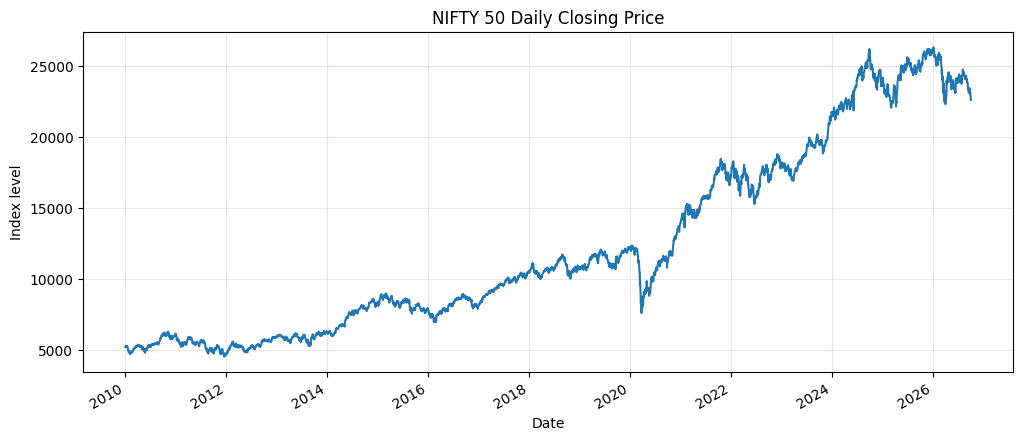

In [66]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Download NIFTY 50 daily data
ticker = "^NSEI"

data = yf.download(
    ticker,
    start="2010-01-01",
    end="2026-10-01",
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Handle the possible MultiIndex column format
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

# Basic cleaning
data = data.sort_index()
data = data[~data.index.duplicated(keep="last")]
data = data.dropna(subset=["Open", "High", "Low", "Close", "Volume"])

print("Dataset shape:", data.shape)
print("\nFirst five observations:")
print(data.head())

print("\nLast five observations:")
print(data.tail())

print("\nMissing values:")
print(data.isna().sum())

# Plot the closing price
data["Close"].plot(figsize=(12, 5), title="NIFTY 50 Daily Closing Price")
plt.xlabel("Date")
plt.ylabel("Index level")
plt.grid(True, alpha=0.3)
plt.show()


## 3. Problem Formulation and Target Variable Construction

### 3.1 Daily Returns

Financial time series often exhibit trends and changing price levels, making raw prices difficult to compare across different periods. To represent relative price movements, we calculate the daily simple return.

Let $$P_t$$ denote the closing price at time \(t\). The daily return is defined as

$$
r_t = \frac{P_t-P_{t-1}}{P_{t-1}}
$$

For example, if the closing price increases from 25,000 to 25,150, the daily return is

$$
r_t = \frac{25150-25000}{25000} = 0.006
$$

This corresponds to a positive return of \(0.6\%\). Returns will subsequently be used to construct predictive features such as lagged returns and rolling volatility.

### 3.2 Formulation as a Binary Classification Problem

The objective of this project is to predict whether the next trading session's closing price will be higher than the current session's closing price.

The target variable is defined as

$$
y_{t+1} =
\begin{cases}
1, & \text{if } P_{t+1}>P_t,\\
0, & \text{if } P_{t+1}\leq P_t.
\end{cases}
$$

Here, a target value of 1 represents an upward market movement, while a target value of 0 represents a flat or downward movement.

This formulation converts the forecasting problem into a supervised binary classification task. The model learns a relationship between historical market features and the corresponding future direction labels.

### 3.3 Target Construction Using Pandas

The `shift(-1)` operation moves the next trading session's closing price onto the current row. Comparing this shifted series with the current closing price allows us to construct the target variable.

For every observation at time \(t\), the target describes the market direction at time \(t+1\). The final observation does not have a known next-session closing price within the downloaded dataset, so its target is undefined.

### 3.4 Prediction Timing and Data Leakage

For this experiment, predictions are assumed to be generated after the current trading session has closed. Therefore, features may use information available up to and including time \(t\), but they must not contain information from time \(t+1\) or later.

Using future information during feature construction or model training would introduce **data leakage**, producing misleading evaluation results.

The target variable is used only as the outcome to be predicted. It must not be included among the input features. Later, the dataset will be divided chronologically into training, validation, and test sets to preserve the temporal order of observations.

The final objective is to evaluate whether the trained models can generalize to unseen market observations rather than merely reproduce patterns in historical data.

In [67]:
# Calculate the close-to-close simple return
data["Return"] = data["Close"].pct_change()

# Obtain the next available trading session's closing price
next_close = data["Close"].shift(-1)

# Construct the next-session direction target
data["Target"] = np.where(
    next_close.isna(),
    np.nan,
    (next_close > data["Close"]).astype(int)
)

print(data[["Close", "Return", "Target"]].head(10))

print("\nTarget distribution:")
print(data["Target"].value_counts(dropna=False))

print("\nTarget proportions:")
print(data["Target"].value_counts(normalize=True))

Price             Close    Return  Target
Date                                     
2010-01-04  5232.200195       NaN     1.0
2010-01-05  5277.899902  0.008734     1.0
2010-01-06  5281.799805  0.000739     0.0
2010-01-07  5263.100098 -0.003540     0.0
2010-01-08  5244.750000 -0.003487     1.0
2010-01-11  5249.399902  0.000887     0.0
2010-01-12  5210.399902 -0.007429     1.0
2010-01-13  5233.950195  0.004520     1.0
2010-01-14  5259.899902  0.004958     0.0
2010-01-15  5252.200195 -0.001464     1.0

Target distribution:
Target
1.0    2179
0.0    1933
NaN       1
Name: count, dtype: int64

Target proportions:
Target
1.0    0.529912
0.0    0.470088
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the statistical properties, distribution, and temporal behaviour of the financial time series before applying machine learning models.

Financial data often exhibit characteristics such as non-normal return distributions, volatility clustering, extreme price movements, and changing market conditions. Investigating these properties helps guide feature engineering and model evaluation.

The following analysis focuses on:

- The distribution of daily returns.
- The frequency of upward and downward market movements.
- Summary statistics and extreme observations.
- Changes in market volatility over time.

EDA is conducted before model training to identify data-quality issues and understand the dataset. Any preprocessing parameters used by the predictive models will subsequently be estimated using training data only, preventing information leakage from validation and test sets.

### 4.1 Distribution of Daily Returns

Daily returns describe the relative changes in the index closing price from one trading session to the next. Examining their distribution helps us understand the typical magnitude of daily movements and the presence of extreme observations.

A histogram provides a visual representation of the frequency of different return values. A return distribution concentrated around zero indicates that small daily movements occur frequently, while observations farther from zero represent larger price changes.

Financial returns may exhibit heavy tails, meaning that extreme movements can occur more frequently than predicted by a normal distribution. This is important because models trained on financial data must contend with both ordinary market fluctuations and unusually large movements.

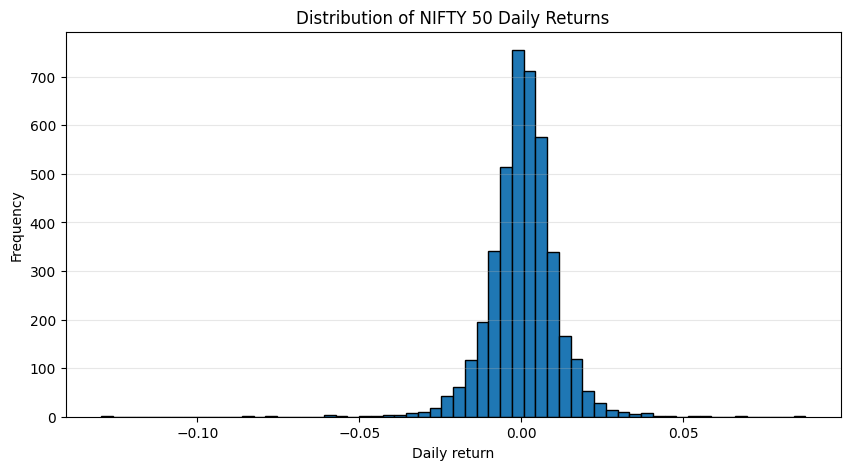

Mean daily return: 0.0004099261389630411
Standard deviation: 0.010351295689649872
Minimum daily return: -0.12980466070471242
Maximum daily return: 0.08763210467115035


In [68]:

# Remove the initial missing return
returns = data["Return"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(returns, bins=60, edgecolor="black")
plt.title("Distribution of NIFTY 50 Daily Returns")
plt.xlabel("Daily return")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Mean daily return:", returns.mean())
print("Standard deviation:", returns.std())
print("Minimum daily return:", returns.min())
print("Maximum daily return:", returns.max())


### 4.2 Distribution of Market Direction Labels

The prediction target is a binary variable that indicates whether the next trading session's closing price is higher than the current session's closing price.

Examining the distribution of these labels helps determine whether the dataset is balanced between the two classes.

If one class occurs substantially more frequently than the other, a model may achieve apparently reasonable accuracy by predominantly predicting the majority class. Therefore, the class distribution must be examined before selecting evaluation metrics and establishing baseline models.

The class proportions are calculated using the number of observations belonging to each class divided by the total number of observations with known labels.

Target counts:
Target
Down or unchanged    1933
Up                   2179
Name: count, dtype: int64

Target proportions:
Target
Down or unchanged    0.470088
Up                   0.529912
Name: proportion, dtype: float64


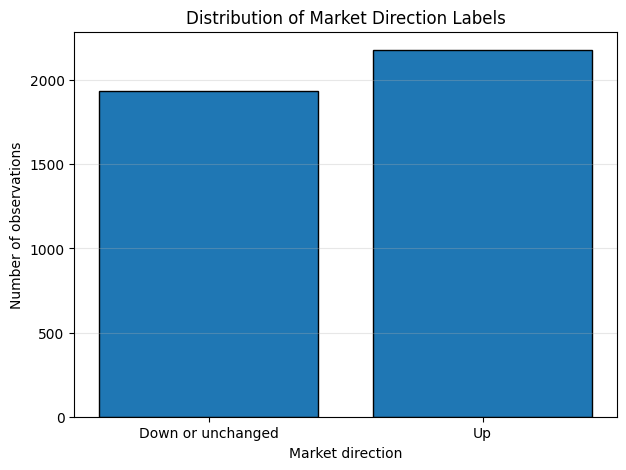

In [69]:

# Exclude observations whose target is undefined
target_counts = data["Target"].value_counts().sort_index()

target_labels = {
    0: "Down or unchanged",
    1: "Up"
}

print("Target counts:")
print(target_counts.rename(index=target_labels))

print("\nTarget proportions:")
print(
    data["Target"]
    .value_counts(normalize=True)
    .sort_index()
    .rename(index=target_labels)
)

plt.figure(figsize=(7, 5))
plt.bar(
    [target_labels[int(i)] for i in target_counts.index],
    target_counts.values,
    edgecolor="black"
)
plt.title("Distribution of Market Direction Labels")
plt.xlabel("Market direction")
plt.ylabel("Number of observations")
plt.grid(axis="y", alpha=0.3)
plt.show()


### 4.3 Statistical Summary of Daily Returns

Descriptive statistics provide a compact numerical summary of the daily return series.

The mean measures the average daily return, while the standard deviation measures the dispersion of returns around their mean. The minimum and maximum identify the most extreme observed movements.

The median represents the middle observation when returns are ordered. Comparing the mean with the median can provide an initial indication of asymmetry in the distribution.

These statistics help characterize the historical data but do not, by themselves, establish that future market direction can be predicted reliably.

In [70]:

# Calculate descriptive statistics for daily returns
return_summary = returns.describe()

print("Descriptive Statistics of Daily Returns")
print(return_summary)

print("\nMedian daily return:", returns.median())
print("Return skewness:", returns.skew())
print("Return excess kurtosis:", returns.kurt())


Descriptive Statistics of Daily Returns
count    4112.000000
mean        0.000410
std         0.010351
min        -0.129805
25%        -0.004803
50%         0.000538
75%         0.006019
max         0.087632
Name: Return, dtype: float64

Median daily return: 0.0005383858727834312
Return skewness: -0.661415180962688
Return excess kurtosis: 11.516451454109067


### 4.4 Rolling Volatility Analysis

Market volatility changes over time. Periods of relatively stable market behaviour may alternate with periods of substantial price fluctuations.

To examine these changes, we calculate the rolling standard deviation of daily returns over a window of 20 trading sessions.

For a window containing \(n\) returns, the sample standard deviation is

$$
\sigma_t =
\sqrt{
\frac{1}{n-1}
\sum_{i=0}^{n-1}
(r_{t-i}-\bar r_t)^2
}
$$

where $$\bar r_t\$$ is the mean return within the rolling window.

Higher rolling volatility indicates greater dispersion in recent daily returns, whereas lower volatility indicates more stable recent price movements.

Rolling volatility will also be considered as a potential predictive feature. When used for prediction at time \(t\), it must be calculated exclusively from returns available up to time \(t\).

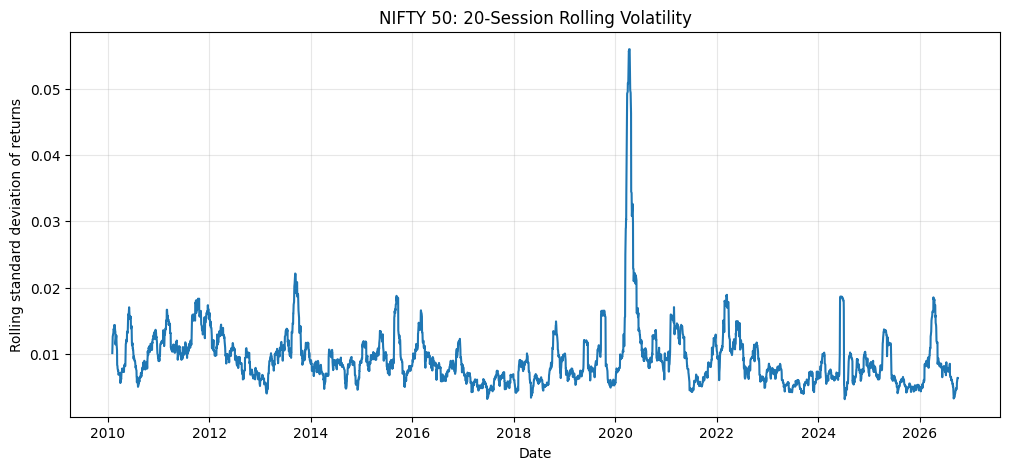

In [71]:

# Calculate volatility over the previous 20 trading sessions
data["Rolling_Volatility_20"] = (
    data["Return"]
    .rolling(window=20)
    .std()
)

plt.figure(figsize=(12, 5))
plt.plot(
    data.index,
    data["Rolling_Volatility_20"]
)
plt.title("NIFTY 50: 20-Session Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Rolling standard deviation of returns")
plt.grid(True, alpha=0.3)
plt.show()


## 5. Feature Engineering

Feature engineering is the process of transforming raw data into informative variables that can be used by machine learning algorithms. In financial time-series modelling, raw closing prices alone may not adequately represent recent market behaviour. Returns, momentum indicators, and rolling statistics provide additional information about historical price movements.

In this project, features are constructed from historical NIFTY 50 market data to predict the direction of the next trading session. The engineered variables will serve as inputs to both a feed-forward neural network and an LSTM-based sequence model.

The following categories of features will be considered:

1. **Lagged returns:** Capture recent historical price movements.
2. **Rolling volatility:** Measure the variability of returns over a recent window.
3. **Moving-average features:** Represent recent price trends relative to historical averages.
4. **Momentum features:** Measure cumulative price changes over selected lookback periods.

All features must be calculated using information available at the prediction time. The future direction label is retained separately as the target variable and must never be included in the input feature matrix.

Feature engineering is performed before the chronological train-validation-test split only when each feature is calculated using strictly backward-looking operations. Any data-dependent preprocessing, such as feature scaling, will be fitted on the training set alone.

The objective is to construct a reproducible feature matrix that allows both neural network architectures to be compared using the same prediction target and evaluation periods.

### 5.1 Lagged Returns

Lagged returns represent price movements observed during previous trading sessions. They allow a model to examine whether recent market movements contain useful information about the next session's direction.

Let \(r_t\) denote the return observed during session \(t\). A lagged-return feature is defined as

$$
X_t^{(k)} = r_{t-k}
$$

where \(k\) represents the number of trading sessions in the past.

For example, \(r_{t-1}\) represents the return from the previous session, while \(r_{t-5}\) represents the return from five sessions earlier.

This project constructs five lagged-return features. Since the prediction is assumed to be made after session \(t\) closes, these features use returns from sessions preceding \(t\), providing a conservative set of historical inputs.

Lagged returns enable the model to investigate short-term patterns, such as persistence or reversal in recent price movements. However, their predictive usefulness must be established empirically rather than assumed.

In [72]:

# Create a separate dataset for feature engineering
feature_data = data.copy()

# Returns from the previous five trading sessions
for lag in range(1, 6):
    feature_data[f"Return_Lag_{lag}"] = (
        feature_data["Return"].shift(lag)
    )

print(
    feature_data[
        ["Return"] +
        [f"Return_Lag_{i}" for i in range(1, 6)]
    ].head(10)
)


Price         Return  Return_Lag_1  Return_Lag_2  Return_Lag_3  Return_Lag_4  \
Date                                                                           
2010-01-04       NaN           NaN           NaN           NaN           NaN   
2010-01-05  0.008734           NaN           NaN           NaN           NaN   
2010-01-06  0.000739      0.008734           NaN           NaN           NaN   
2010-01-07 -0.003540      0.000739      0.008734           NaN           NaN   
2010-01-08 -0.003487     -0.003540      0.000739      0.008734           NaN   
2010-01-11  0.000887     -0.003487     -0.003540      0.000739      0.008734   
2010-01-12 -0.007429      0.000887     -0.003487     -0.003540      0.000739   
2010-01-13  0.004520     -0.007429      0.000887     -0.003487     -0.003540   
2010-01-14  0.004958      0.004520     -0.007429      0.000887     -0.003487   
2010-01-15 -0.001464      0.004958      0.004520     -0.007429      0.000887   

Price       Return_Lag_5  
Date        

### 5.2 Rolling Volatility Features

Volatility measures the variability of financial returns. It provides information about the intensity of recent market fluctuations, which may change across different market conditions.

For a window of \(n\) observations, rolling volatility is calculated as the sample standard deviation of the returns within that window:

$$
\sigma_t^{(n)}
=
\sqrt{
\frac{1}{n-1}
\sum_{i=0}^{n-1}
(r_{t-i}-\bar r_t^{(n)})^2
}
$$

where \(\bar r_t^{(n)}\) is the mean return over the same window.

We calculate rolling volatility over 5, 10, and 20 trading sessions. Shorter windows capture more recent fluctuations, while longer windows represent volatility over a broader period.

The rolling windows include only the current and preceding observations. Since all these observations are available at the assumed prediction time, the features do not require future information.

These variables allow the models to investigate whether recent market uncertainty is associated with changes in the probability of an upward or downward movement.

In [73]:

# Rolling standard deviation of returns
for window in [5, 10, 20]:
    feature_data[f"Volatility_{window}"] = (
        feature_data["Return"].rolling(window=window).std()
    )

print(
    feature_data[
        ["Volatility_5", "Volatility_10", "Volatility_20"]
    ].tail(10)
)


Price       Volatility_5  Volatility_10  Volatility_20
Date                                                  
2026-09-17      0.006566       0.005245       0.004832
2026-09-18      0.006751       0.005575       0.004603
2026-09-21      0.006804       0.005727       0.004689
2026-09-22      0.003137       0.005667       0.004707
2026-09-23      0.003303       0.005846       0.004728
2026-09-24      0.008806       0.007326       0.005703
2026-09-25      0.008820       0.007412       0.005813
2026-09-28      0.010156       0.008666       0.006397
2026-09-29      0.010199       0.008034       0.006393
2026-09-30      0.008567       0.007774       0.006384


### 5.3 Moving-Average Features

Moving averages smooth short-term fluctuations in price data and help describe the recent direction of the market.

The simple moving average over \(n\) trading sessions is defined as

$$
SMA_t^{(n)}
=
\frac{1}{n}\sum_{i=0}^{n-1}P_{t-i}
$$

where \(P_t\) denotes the closing price at time \(t\).

We consider moving averages over 5 and 20 trading sessions. Rather than using the moving-average levels directly, we calculate the relative difference between the current closing price and each moving average:

$$
MA\_Ratio_t^{(n)}
=
\frac{P_t}{SMA_t^{(n)}}-1
$$

A positive ratio indicates that the closing price is above its moving average, whereas a negative ratio indicates that it is below the average.

Normalizing the difference relative to the moving average makes the feature easier to compare across different index levels. These features represent recent price trends without requiring the model to learn directly from the absolute magnitude of the index.

In [74]:

# Calculate moving-average ratios
for window in [5, 20]:
    moving_average = (
        feature_data["Close"].rolling(window=window).mean()
    )

    feature_data[f"MA_Ratio_{window}"] = (
        feature_data["Close"] / moving_average - 1
    )

print(
    feature_data[
        ["Close", "MA_Ratio_5", "MA_Ratio_20"]
    ].tail(10)
)


Price              Close  MA_Ratio_5  MA_Ratio_20
Date                                             
2026-09-17  23270.599609   -0.001113    -0.023602
2026-09-18  23346.400391    0.003272    -0.018598
2026-09-21  23414.300781    0.006050    -0.014008
2026-09-22  23329.000000    0.000576    -0.015755
2026-09-23  23446.800781    0.003655    -0.008929
2026-09-24  23063.099609   -0.011013    -0.022784
2026-09-25  23140.500000   -0.005938    -0.017526
2026-09-28  22780.250000   -0.016054    -0.029948
2026-09-29  22716.199219   -0.013599    -0.029857
2026-09-30  22620.449219   -0.010656    -0.030977


### 5.4 Momentum Features

Momentum measures the cumulative price movement over a specified historical period. It helps represent whether the market has experienced an overall increase or decrease in price over a recent window.

The momentum over \(n\) trading sessions is defined as

$$
M_t^{(n)}
=
\frac{P_t-P_{t-n}}{P_{t-n}}
$$

Equivalently,

$$
M_t^{(n)}
=
\frac{P_t}{P_{t-n}}-1
$$

We calculate momentum over 5 and 10 trading sessions. Positive momentum indicates that the current closing price exceeds its value at the beginning of the selected window, while negative momentum indicates a decline.

Momentum features summarize cumulative price changes and complement lagged returns, which describe individual historical movements. Since the calculation uses only the current and past closing prices, it is compatible with the defined prediction timing.

In [75]:

# Calculate momentum over 5 and 10 trading sessions
for window in [5, 10]:
    feature_data[f"Momentum_{window}"] = (
        feature_data["Close"].pct_change(periods=window)
    )

print(
    feature_data[
        ["Momentum_5", "Momentum_10"]
    ].tail(10)
)


Price       Momentum_5  Momentum_10
Date                               
2026-09-17   -0.006867    -0.026923
2026-09-18   -0.005597    -0.022077
2026-09-21    0.000692    -0.020228
2026-09-22    0.009101    -0.018930
2026-09-23    0.009872    -0.007967
2026-09-24   -0.008917    -0.015722
2026-09-25   -0.008819    -0.014367
2026-09-28   -0.027080    -0.026406
2026-09-29   -0.026268    -0.017406
2026-09-30   -0.035244    -0.025720


### 5.5 Feature Matrix Construction and Data Cleaning

After constructing the predictive features, we combine them into a feature matrix \(X\) and define the target vector \(y\).

Let the engineered feature vector at time \(t\) be

$$
X_t =
\begin{bmatrix}
r_{t-1} & \cdots & r_{t-5} &
\sigma_t^{(5)} & \sigma_t^{(10)} &
\sigma_t^{(20)} &
MA\_Ratio_t^{(5)} &
MA\_Ratio_t^{(20)} &
M_t^{(5)} &
M_t^{(10)}
\end{bmatrix}
$$

The target \(y_{t+1}\) represents the direction of the next trading session, as defined in Section 3.

The initial observations may contain missing feature values because lagged variables and rolling statistics require a sufficient history of observations. The final observation also lacks a known future target within the downloaded dataset.

These rows must be removed before modelling. We retain only observations for which every selected feature and the target are available.

The resulting dataset contains the information required for supervised learning. It will subsequently be divided into chronological training, validation, and test sets. Feature scaling will be fitted exclusively on the training set to prevent information leakage.

The target variable is explicitly excluded from the feature matrix to ensure that the models learn from historical inputs rather than the answer they are expected to predict.

In [76]:

# Select predictive features
feature_columns = (
    [f"Return_Lag_{i}" for i in range(1, 6)]
    + [f"Volatility_{i}" for i in [5, 10, 20]]
    + [f"MA_Ratio_{i}" for i in [5, 20]]
    + [f"Momentum_{i}" for i in [5, 10]]
)

# Keep only features and the target
model_data = feature_data[feature_columns + ["Target"]].copy()

# Remove rows with missing features or unknown targets
model_data = model_data.dropna()

# Separate the feature matrix and target vector
X = model_data[feature_columns].copy()
y = model_data["Target"].astype(int).copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Number of features:", len(feature_columns))

print("\nFeature columns:")
print(feature_columns)

print("\nFirst five rows of X:")
print(X.head())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nDate range:")
print(model_data.index.min(), "to", model_data.index.max())

print("\nMissing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())


Feature matrix shape: (4092, 12)
Target vector shape: (4092,)
Number of features: 12

Feature columns:
['Return_Lag_1', 'Return_Lag_2', 'Return_Lag_3', 'Return_Lag_4', 'Return_Lag_5', 'Volatility_5', 'Volatility_10', 'Volatility_20', 'MA_Ratio_5', 'MA_Ratio_20', 'Momentum_5', 'Momentum_10']

First five rows of X:
Price       Return_Lag_1  Return_Lag_2  Return_Lag_3  Return_Lag_4  \
Date                                                                 
2010-02-02      0.003615      0.003041      0.002916     -0.030911   
2010-02-03     -0.014205      0.003615      0.003041      0.002916   
2010-02-04      0.021066     -0.014205      0.003615      0.003041   
2010-02-05     -0.017539      0.021066     -0.014205      0.003615   
2010-02-08     -0.026149     -0.017539      0.021066     -0.014205   

Price       Return_Lag_5  Volatility_5  Volatility_10  Volatility_20  \
Date                                                                   
2010-02-02     -0.005580      0.015292       0.011

### 5.6 Inspection of Engineered Features

Before proceeding to model development, we inspect the engineered features to verify that the feature matrix has the expected dimensions and contains no missing values.

The features represent different aspects of historical market behaviour: lagged returns describe recent price movements, rolling volatility captures fluctuations in returns, moving-average ratios represent price trends, and momentum measures cumulative price changes.

The feature matrix and target vector must have matching indices and the same number of observations. Each row must correspond to a valid prediction example, with the features available at the assumed prediction time and the target representing the following trading session.

This inspection is the final data-quality check before chronological dataset splitting and model training.

                count      mean       std       min       25%       50%  \
Price                                                                     
Return_Lag_1   4092.0  0.000430  0.010351 -0.129805 -0.004794  0.000551   
Return_Lag_2   4092.0  0.000435  0.010348 -0.129805 -0.004789  0.000552   
Return_Lag_3   4092.0  0.000435  0.010348 -0.129805 -0.004789  0.000552   
Return_Lag_4   4092.0  0.000431  0.010357 -0.129805 -0.004789  0.000552   
Return_Lag_5   4092.0  0.000429  0.010357 -0.129805 -0.004794  0.000551   
Volatility_5   4092.0  0.008636  0.005692  0.000979  0.005191  0.007409   
Volatility_10  4092.0  0.009052  0.005005  0.001966  0.006058  0.008038   
Volatility_20  4092.0  0.009269  0.004609  0.003169  0.006484  0.008386   
MA_Ratio_5     4092.0  0.000776  0.011399 -0.095203 -0.005782  0.001378   
MA_Ratio_20    4092.0  0.003701  0.025996 -0.260401 -0.010846  0.005573   
Momentum_5     4092.0  0.002163  0.023172 -0.190239 -0.010803  0.003194   
Momentum_10    4092.0  0.

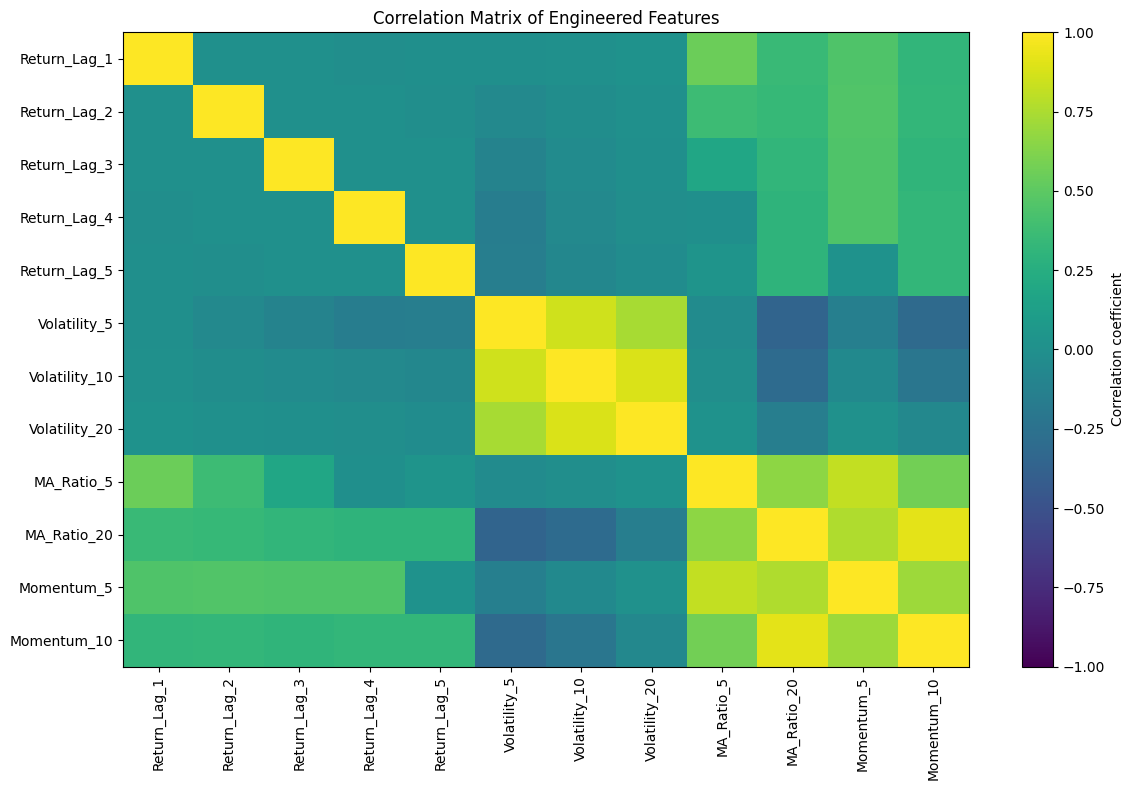

In [77]:

# Inspect feature distributions
print(X.describe().T)

# Visualize the correlation matrix
correlation_matrix = X.corr()

plt.figure(figsize=(12, 8))
plt.imshow(correlation_matrix, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=90
)
plt.yticks(range(len(feature_columns)), feature_columns)

plt.title("Correlation Matrix of Engineered Features")
plt.tight_layout()
plt.show()


## 6. Chronological Data Splitting and Preprocessing

### 6.1 Motivation for Chronological Splitting

In supervised machine learning, a dataset is commonly divided into training, validation, and test subsets. The training set is used to estimate model parameters, the validation set supports model selection and hyperparameter tuning, and the test set provides a final evaluation on unseen observations.

For financial time-series data, these subsets must preserve chronological order. Randomly assigning observations to different subsets can allow a model to train on later market conditions while being evaluated on earlier ones. This does not accurately represent the intended forecasting task.

Let the complete dataset contain \(N\) valid observations. We divide it into three consecutive subsets:

- **Training set:** The earliest 70% of observations.
- **Validation set:** The subsequent 15% of observations.
- **Test set:** The most recent 15% of observations.

The chronological ordering is therefore

$$
D_{\text{train}}
\prec D_{\text{validation}}
\prec D_{\text{test}}
$$

where \(\prec\) indicates that all observations in one subset precede those in the next subset.

The training set is used to fit the model, the validation set is used for model selection, and the test set is reserved for the final comparison of models.

### 6.2 Feature Scaling

The engineered features have different numerical scales. For example, returns and momentum are generally small decimal values, whereas volatility and moving-average ratios have their own distributions.

Standardization transforms each feature using

$$
z = \frac{x-\mu}{\sigma}
$$

where \(\mu\) is the feature mean and \(\sigma\) is its standard deviation, both estimated from the training data.

The training-set statistics are then applied unchanged to the validation and test sets. This prevents information from future observations from influencing the preprocessing parameters.

The scaler must never be fitted independently on the validation or test set. Doing so would introduce information about the distributions of observations that are supposed to remain unseen during training.

### 6.3 Experimental Integrity

The split is performed before fitting the scaler or training any model. The target labels remain separate from the input features.

The final test set will be used only after model development and selection are complete. This provides a more reliable assessment of generalization to later market observations.

The 70:15:15 split is a practical initial choice rather than a universally optimal ratio. Its suitability depends on the size of the dataset and the number of observations available for evaluation.

In [78]:

# Define chronological split proportions
train_ratio = 0.70
val_ratio = 0.15

# Calculate split boundaries
n = len(model_data)
train_end = int(n * train_ratio)
val_end = int(n * (train_ratio + val_ratio))

# Split features and targets without shuffling
X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:val_end].copy()
X_test = X.iloc[val_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:val_end].copy()
y_test = y.iloc[val_end:].copy()

# Inspect partition sizes
print("Total observations:", n)
print("\nTraining observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Test observations:", len(X_test))

print("\nDate ranges:")
print("Train:", X_train.index.min(), "to", X_train.index.max())
print("Validation:", X_val.index.min(), "to", X_val.index.max())
print("Test:", X_test.index.min(), "to", X_test.index.max())


Total observations: 4092

Training observations: 2864
Validation observations: 614
Test observations: 614

Date ranges:
Train: 2010-02-02 00:00:00 to 2021-10-08 00:00:00
Validation: 2021-10-11 00:00:00 to 2024-04-04 00:00:00
Test: 2024-04-05 00:00:00 to 2026-09-29 00:00:00


### 6.3 Standardization of Features

Standardization is performed using `StandardScaler` from scikit-learn. For each feature, the scaler estimates the mean and standard deviation from the training set and uses them to transform the observations.

For a given feature \(j\), the transformation is

$$
z_{ij} = \frac{x_{ij}-\mu_j}{\sigma_j}
$$

where \$$(x_{ij}\)$$ is the original value of feature \(j\) for observation \(i\), while $$\(\mu_j\)$$ and $$\(\sigma_j\)$$ are estimated exclusively from the training observations.

The fitted transformation is applied to the training, validation, and test subsets without refitting the scaler.

Standardization is useful for neural networks because differences in feature scales can affect gradient-based optimization. It also makes the engineered features more comparable numerically.

The original unscaled data are retained separately, allowing the transformation to be reproduced and the original feature values to remain available for interpretation.

In [79]:

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit only on the training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test using training statistics
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

print("\nTraining feature means after scaling:")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining feature standard deviations after scaling:")
print(np.round(X_train_scaled.std(axis=0), 4))


Scaled training shape: (2864, 12)
Scaled validation shape: (614, 12)
Scaled test shape: (614, 12)

Training feature means after scaling:
[ 0.  0. -0. -0. -0.  0. -0. -0. -0.  0.  0.  0.]

Training feature standard deviations after scaling:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 6.4 Target Distribution Across Data Subsets

The proportions of upward and downward market movements may vary over time. Examining the target distribution in each subset helps determine whether the training, validation, and test periods have similar class frequencies.

For each subset, we calculate the number and proportion of observations belonging to each class.

Differences between these distributions may reflect changing market conditions rather than errors in the data. Such differences are important when interpreting accuracy, precision, recall, and F1-score.

The target distribution is examined separately for each partition. No observations are moved between partitions to force equal class proportions, because doing so would undermine the chronological evaluation design.

In [80]:

# Compare target distributions across partitions
target_splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

for name, target in target_splits.items():
    print(f"\n{name} target counts:")
    print(target.value_counts().sort_index())

    print(f"\n{name} target proportions:")
    print(target.value_counts(normalize=True).sort_index())



Train target counts:
Target
0    1334
1    1530
Name: count, dtype: int64

Train target proportions:
Target
0    0.465782
1    0.534218
Name: proportion, dtype: float64

Validation target counts:
Target
0    284
1    330
Name: count, dtype: int64

Validation target proportions:
Target
0    0.462541
1    0.537459
Name: proportion, dtype: float64

Test target counts:
Target
0    304
1    310
Name: count, dtype: int64

Test target proportions:
Target
0    0.495114
1    0.504886
Name: proportion, dtype: float64


### 6.5 Visualization of the Data Partitions

A chronological visualization provides a clear representation of the periods assigned to training, validation, and testing.

The plot displays the closing price across the full study period, with vertical boundaries indicating the transitions between subsets. This makes it possible to verify that the test set contains the latest observations and that the partitions do not overlap.

The visualization also helps identify major changes in market levels across the evaluation periods. Such changes may influence model performance and should be considered when interpreting the final results.

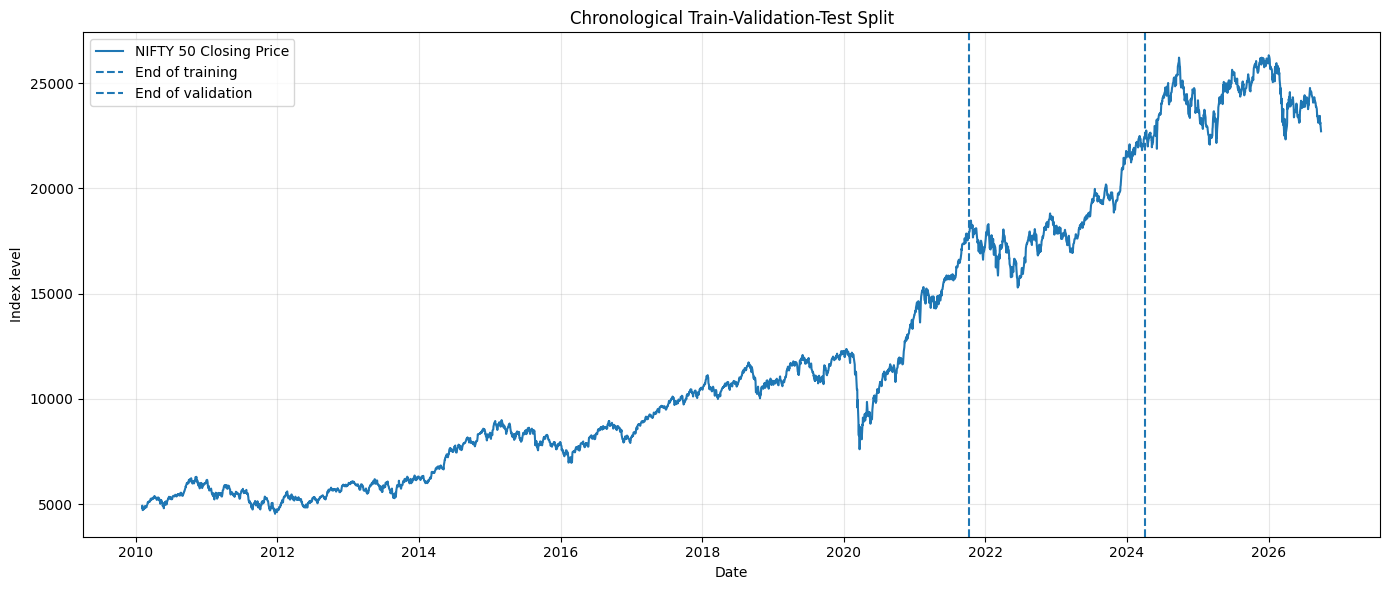

In [81]:

plt.figure(figsize=(14, 6))

plt.plot(
    model_data.index,
    data.loc[model_data.index, "Close"],
    label="NIFTY 50 Closing Price"
)

plt.axvline(
    X_train.index[-1],
    linestyle="--",
    label="End of training"
)

plt.axvline(
    X_val.index[-1],
    linestyle="--",
    label="End of validation"
)

plt.title("Chronological Train-Validation-Test Split")
plt.xlabel("Date")
plt.ylabel("Index level")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 6.6 Verification of Data Integrity

Before training the models, we verify that the partitions are chronologically ordered, contain no missing feature values, and have matching feature and target dimensions.

We also confirm that the scaler was fitted using the training subset only.

These checks reduce the risk of accidental preprocessing errors and help ensure that subsequent performance comparisons are based on a consistent evaluation protocol.

Once these checks are satisfied, the scaled datasets are ready for baseline modelling and neural network training.

In [82]:

# Check feature and target dimensions
assert X_train_scaled.shape[0] == len(y_train)
assert X_val_scaled.shape[0] == len(y_val)
assert X_test_scaled.shape[0] == len(y_test)

# Check chronological ordering and non-overlapping partitions
assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()

# Check for missing values
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

# Confirm that the scaled training data are standardized
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-7)
assert np.allclose(X_train_scaled.std(axis=0), 1, atol=1e-7)

print("All data integrity checks passed.")
print("Training, validation, and test sets are ready.")


All data integrity checks passed.
Training, validation, and test sets are ready.


## 7. Baseline Models and Performance Evaluation

### 7.1 Motivation for Baseline Modelling

A baseline model provides a reference against which more complex machine learning models can be evaluated. Without a baseline, a model's classification accuracy alone does not establish whether it has learned useful predictive patterns.

Financial market direction can be difficult to predict because daily price movements contain substantial uncertainty. Consequently, even a model with apparently reasonable accuracy may fail to outperform a simple prediction strategy.

This section introduces two baseline classifiers:

1. **Majority-class classifier:** Predicts the most frequent target class observed in the training data for every input observation.
2. **Logistic regression:** Estimates the probability of an upward market movement using a linear combination of the engineered input features, followed by a logistic transformation.

The majority-class classifier establishes a simple reference level of performance. Logistic regression provides a conventional statistical learning benchmark against which the nonlinear neural network architectures can be compared.

Both models are trained using the training set. Their initial performance is evaluated on the validation set, which is used for model development and comparison. The test set remains reserved for the final evaluation after model selection is complete.

The evaluation uses accuracy, precision, recall, F1-score, and the confusion matrix. These metrics provide complementary perspectives on classification performance and help identify whether a model performs differently across the two market-direction classes.

### 7.2 Evaluation Metrics

The performance of a binary classifier can be described using four possible outcomes:

- **True Positive (TP):** An upward movement is correctly predicted as upward.
- **True Negative (TN):** A flat or downward movement is correctly predicted as flat or downward.
- **False Positive (FP):** A flat or downward movement is incorrectly predicted as upward.
- **False Negative (FN):** An upward movement is incorrectly predicted as flat or downward.

The following metrics are used to evaluate the classifiers.

**Accuracy** measures the proportion of all predictions that are correct:

$$
\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}
$$

**Precision** measures the proportion of predicted upward movements that are actually upward:

$$
\text{Precision}=\frac{TP}{TP+FP}
$$

**Recall** measures the proportion of actual upward movements correctly identified:

$$
\text{Recall}=\frac{TP}{TP+FN}
$$

**F1-score** is the harmonic mean of precision and recall:

$$
F_1=2\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}}
$$

Precision and recall are calculated for the upward class when reporting the positive-class metrics. The classification report will also provide per-class results and macro averages.

Accuracy alone may be misleading if the two classes have unequal frequencies. The confusion matrix and class-specific metrics therefore provide additional information about the types of prediction errors made by each model.

In [83]:

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


### 7.3 Majority-Class Classifier

The majority-class classifier is a simple baseline that predicts the most frequent target class in the training set for every observation, regardless of its feature values.

Let \(N_0\) and \(N_1\) denote the numbers of observations belonging to classes 0 and 1 in the training set. The classifier predicts

$$
\hat y =
\begin{cases}
0, & N_0 \geq N_1,\\
1, & N_1 > N_0.
\end{cases}
$$

This model does not learn relationships between market features and future direction. Instead, it establishes the performance that can be obtained by always predicting the dominant class.

If a more complex model cannot outperform this benchmark on unseen validation observations, its predictive value is questionable. The majority-class baseline is therefore an essential reference for evaluating logistic regression and the subsequent neural networks.

In [84]:

# Initialize the majority-class classifier
majority_model = DummyClassifier(strategy="most_frequent")

# Train using the training set only
majority_model.fit(X_train_scaled, y_train)

# Predict market direction on the validation set
y_val_pred_majority = majority_model.predict(X_val_scaled)

print("Majority class predicted:", majority_model.classes_[
    majority_model.class_prior_.argmax()
])

print("\nValidation Accuracy:",
      accuracy_score(y_val, y_val_pred_majority))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_majority,
        labels=[0, 1],
        target_names=["Down/Unchanged", "Up"],
        zero_division=0
    )
)


Majority class predicted: 1

Validation Accuracy: 0.5374592833876222

Classification Report:
                precision    recall  f1-score   support

Down/Unchanged       0.00      0.00      0.00       284
            Up       0.54      1.00      0.70       330

      accuracy                           0.54       614
     macro avg       0.27      0.50      0.35       614
  weighted avg       0.29      0.54      0.38       614



### 7.4 Logistic Regression Classifier

Logistic regression is a supervised classification algorithm that estimates the probability of an observation belonging to a particular class. Despite its name, it is commonly used for binary classification rather than continuous-value regression.

For an input feature vector \(X\), the model computes a linear combination of the features:

$$
z = \mathbf{w}^{T}\mathbf{x}+b
$$

where \(\mathbf{w}\) is the vector of learned coefficients and \(b\) is the intercept.

The linear output is transformed into a probability using the sigmoid function:

$$
P(y=1\mid\mathbf{x})
=
\sigma(z)
=
\frac{1}{1+e^{-z}}
$$

The predicted class is obtained by applying a decision threshold, conventionally 0.5:

$$
\hat y =
\begin{cases}
1, & P(y=1\mid\mathbf{x})\geq 0.5,\\
0, & P(y=1\mid\mathbf{x})<0.5.
\end{cases}
$$

Logistic regression provides a useful benchmark because it can learn relationships between the engineered features and market direction while remaining relatively simple to interpret.

The model is trained on the scaled training features. Its regularization strength is initially left at the scikit-learn default, so that this experiment establishes a baseline before hyperparameter tuning.

In [85]:

# Initialize logistic regression
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Predict validation labels
y_val_pred_logistic = logistic_model.predict(X_val_scaled)

# Obtain predicted probabilities for the upward class
y_val_prob_logistic = logistic_model.predict_proba(X_val_scaled)[:, 1]

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_logistic))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_logistic,
        labels=[0, 1],
        target_names=["Down/Unchanged", "Up"],
        zero_division=0
    )
)


Validation Accuracy: 0.5423452768729642

Classification Report:
                precision    recall  f1-score   support

Down/Unchanged       0.52      0.17      0.26       284
            Up       0.55      0.86      0.67       330

      accuracy                           0.54       614
     macro avg       0.53      0.52      0.46       614
  weighted avg       0.53      0.54      0.48       614



### 7.5 Comparative Evaluation of Baseline Models

The majority-class classifier and logistic regression are evaluated on the same validation observations. Using a common evaluation period ensures that differences in reported performance arise from the models' predictions rather than differences in the evaluated data.

The comparison includes accuracy, precision, recall, and F1-score for the upward class. These metrics help determine whether logistic regression identifies useful patterns beyond the dominant-class prediction strategy.

No model is assumed to be superior before the results are observed. The measured performance will guide subsequent experiments with feed-forward neural networks and LSTM models.

The test set is not used in this comparison, preserving it for the final evaluation of the selected models.

In [86]:

# Collect validation predictions
baseline_predictions = {
    "Majority Class": y_val_pred_majority,
    "Logistic Regression": y_val_pred_logistic
}

# Calculate evaluation metrics
baseline_results = []

for model_name, predictions in baseline_predictions.items():
    baseline_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

baseline_results = pd.DataFrame(baseline_results)

print(baseline_results.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-Score
     Majority Class    0.5375     0.5375  1.0000    0.6992
Logistic Regression    0.5423     0.5472  0.8606    0.6690


### 7.6 Confusion Matrix Analysis

A confusion matrix provides a detailed breakdown of correct and incorrect classifications.

For binary classification, the confusion matrix is represented as

$$
C =
\begin{bmatrix}
TN & FP\\
FN & TP
\end{bmatrix}
$$

Rows correspond to the actual classes, while columns correspond to the predicted classes.

The diagonal entries represent correct predictions. The off-diagonal entries represent errors: false positives and false negatives.

Comparing the confusion matrices helps reveal whether a model simply predicts the dominant class or identifies both upward and downward movements. This is particularly useful when the market-direction classes are not equally represented.

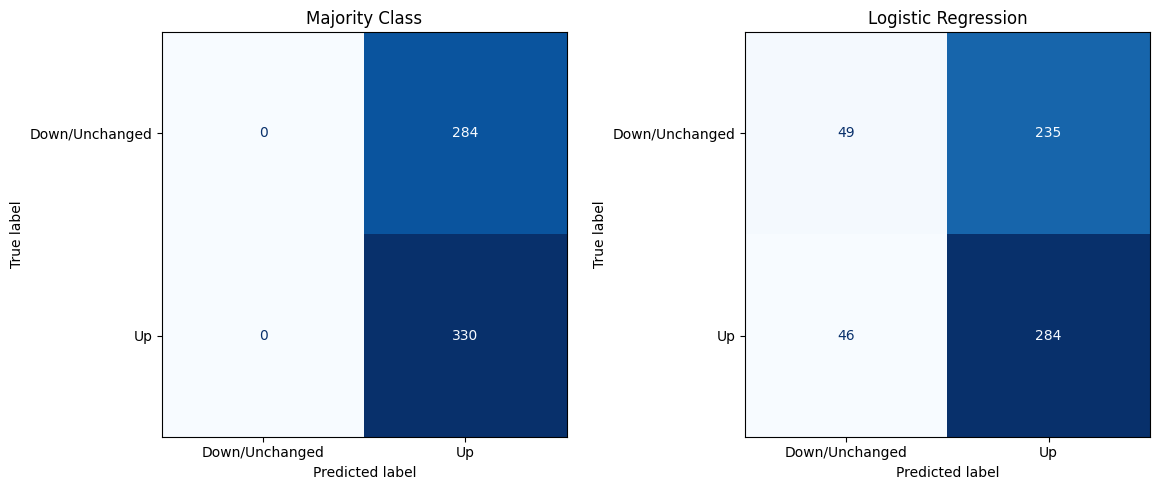

In [87]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, predictions) in zip(
    axes, baseline_predictions.items()
):
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Down/Unchanged", "Up"]
    )

    display.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()


### 7.7 Visualization of Baseline Performance

A visual comparison makes it easier to identify differences in the validation performance of the two baseline classifiers.

The metrics are plotted separately because accuracy, precision, recall, and F1-score measure different aspects of classification quality. In particular, the F1-score balances precision and recall, while accuracy measures overall correctness.

The results should be interpreted collectively rather than relying on a single metric. A model with higher accuracy may still perform poorly at identifying upward movements if its predictions are biased toward the other class.

The baseline results will serve as a reference for the neural network experiments in the subsequent sections.

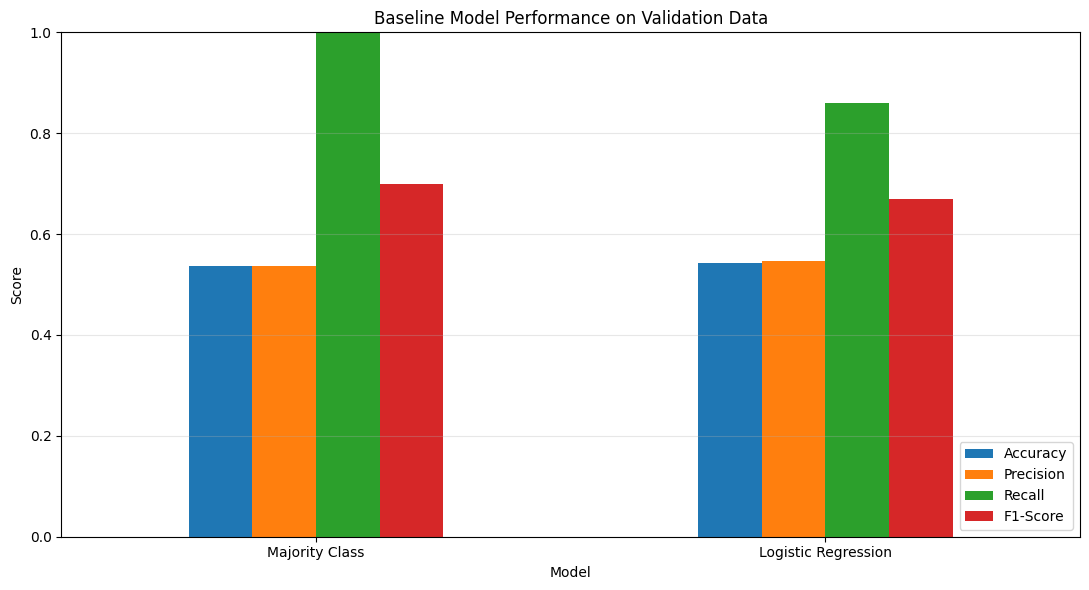

In [88]:

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

baseline_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Baseline Model Performance on Validation Data")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 8. Feed-Forward Neural Network (FNN)

### 8.1 Introduction

A feed-forward neural network is a supervised learning model composed of interconnected layers of artificial neurons. Information flows from the input layer through one or more hidden layers to an output layer, without recurrent connections between earlier and later states.

Unlike logistic regression, which models a linear combination of input features before applying a sigmoid transformation, a neural network with nonlinear activation functions can learn more complex relationships between its inputs and target.

In this project, the FNN receives the engineered financial features developed in Section 5. These include lagged returns, rolling volatility, moving-average ratios, and momentum indicators. Its objective is to estimate the probability that the next trading session's closing price will be higher than the current session's closing price.

The model is implemented using PyTorch. Training involves repeatedly computing predictions, measuring classification error, calculating gradients through backpropagation, and updating the network's parameters using an optimization algorithm.

The validation set is used to monitor generalization and select the best-performing model during training. The test set remains reserved for the final evaluation after model selection is complete.

### 8.2 Architecture and Mathematical Formulation

The FNN consists of an input layer, two hidden layers, and a single output neuron.

The input vector is

$$
\mathbf{x}\in\mathbb{R}^{d}
$$

where \(d\) is the number of engineered features.

The first hidden layer computes

$$
\mathbf{h}_1 =
\operatorname{ReLU}(\mathbf{W}_1\mathbf{x}+\mathbf{b}_1)
$$

The second hidden layer computes

$$
\mathbf{h}_2 =
\operatorname{ReLU}(\mathbf{W}_2\mathbf{h}_1+\mathbf{b}_2)
$$

where the ReLU activation function is

$$
\operatorname{ReLU}(z)=\max(0,z).
$$

The output neuron produces a scalar logit:

$$
z = \mathbf{W}_3\mathbf{h}_2+b_3.
$$

Applying the sigmoid function converts this logit into the estimated probability of an upward market movement:

$$
\hat p = \frac{1}{1+e^{-z}}.
$$

A probability of at least 0.5 corresponds to a predicted upward movement; otherwise, the predicted class is 0.

### Loss Function

We use binary cross-entropy with logits, implemented by PyTorch's `BCEWithLogitsLoss`. This combines the sigmoid operation and binary cross-entropy loss into a numerically stable calculation.

For an observation with target \(y\in\{0,1\}\) and logit \(z\), the loss is

$$
\mathcal{L}(y,z)
=
-\left[
y\log(\sigma(z))
+
(1-y)\log(1-\sigma(z))
\right].
$$

The training objective is to minimize the average loss over the training observations.

### Optimization

The network parameters are optimized using Adam, an adaptive gradient-based optimization algorithm. Gradients are calculated through backpropagation, and the parameters are updated iteratively to reduce the training loss.

The hidden layers allow the model to represent nonlinear relationships between engineered features. However, additional model complexity does not guarantee improved forecasting performance, so validation results must be compared against the baseline models.

### 8.3 Data Preparation for PyTorch

PyTorch neural networks operate on tensors rather than pandas DataFrames and Series. We therefore convert the scaled feature matrices and target vectors into PyTorch tensors.

The input features are represented using 32-bit floating-point values. The binary targets are also represented as floating-point values because `BCEWithLogitsLoss` expects targets in this format.

The feature dimensions must remain consistent across the training, validation, and test sets. The test tensors are prepared here but will not be used to update model parameters or select the best training epoch.

The training dataset is divided into mini-batches. Mini-batch training allows the model to update its parameters using subsets of observations rather than processing the entire training dataset in one gradient update.

In [89]:

import copy
import random

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
)
X_val_tensor = torch.tensor(
    X_val_scaled, dtype=torch.float32
)
X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
)
y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
)
y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
)

# Create a mini-batch training loader
train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

print("Training tensor shape:", X_train_tensor.shape)
print("Validation tensor shape:", X_val_tensor.shape)
print("Test tensor shape:", X_test_tensor.shape)


Using device: cpu
Training tensor shape: torch.Size([2864, 12])
Validation tensor shape: torch.Size([614, 12])
Test tensor shape: torch.Size([614, 12])


### 8.4 FNN Model Implementation

The architecture is implemented as a PyTorch neural network using the `nn.Module` base class.

The input layer accepts the engineered features. The first hidden layer contains 64 neurons, and the second contains 32 neurons. ReLU activations introduce nonlinearity between the layers, while the final linear layer produces one logit for binary classification.

The output layer does not include a sigmoid activation because `BCEWithLogitsLoss` handles the sigmoid transformation internally when computing the loss.

This architecture provides a compact initial neural network. Its hidden-layer sizes are hyperparameters that could be adjusted later using validation performance, but the initial configuration is kept fixed to establish a reproducible benchmark.

In [90]:

class FeedForwardNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


input_dim = X_train_tensor.shape[1]

fnn_model = FeedForwardNN(input_dim).to(device)

print(fnn_model)

total_parameters = sum(
    parameter.numel()
    for parameter in fnn_model.parameters()
    if parameter.requires_grad
)

print("\nNumber of trainable parameters:", total_parameters)


FeedForwardNN(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

Number of trainable parameters: 2945


### 8.5 Model Training Configuration

Training requires a loss function and an optimizer.

The binary cross-entropy loss with logits measures the discrepancy between the predicted logits and the true binary labels. Adam updates the trainable parameters using gradients computed through backpropagation.

The learning rate controls the size of parameter updates. A learning rate that is too high may cause unstable optimization, while one that is too low may result in slow convergence.

We initially use a learning rate of 0.001 and a batch size of 64. The network is trained for a maximum of 100 epochs.

An epoch represents one complete pass through the training dataset. After each epoch, the model is evaluated on the validation set. The model with the lowest validation loss is retained, and training stops early if validation loss fails to improve for a specified number of consecutive epochs.

Early stopping helps reduce overfitting by preventing unnecessary training after validation performance stops improving. The validation set is used only for monitoring and model selection, not for gradient updates.

In [91]:

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    fnn_model.parameters(),
    lr=0.001
)

MAX_EPOCHS = 100
PATIENCE = 12

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": []
}

best_model_state = None


### 8.6 Training and Validation Loop

The network is trained through repeated forward and backward passes.

For each mini-batch, the model first computes its logits. The loss function measures prediction error, and backpropagation calculates the gradients of the loss with respect to the model parameters. The optimizer then updates the parameters.

After completing each epoch, the model is evaluated on the entire validation set. Validation loss is calculated without updating the model parameters.

The model state is saved whenever validation loss reaches a new minimum. If the validation loss does not improve for 12 consecutive epochs, early stopping terminates training.

The best saved model is subsequently restored for evaluation. This avoids automatically treating the final epoch as the best-performing model.

In [92]:

for epoch in range(MAX_EPOCHS):

    # Training phase
    fnn_model.train()
    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        logits = fnn_model(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        running_train_loss += (
            loss.item() * len(batch_X)
        )

    train_loss = (
        running_train_loss / len(train_dataset)
    )

    # Validation phase
    fnn_model.eval()

    with torch.no_grad():
        val_logits = fnn_model(
            X_val_tensor.to(device)
        )

        val_loss = criterion(
            val_logits,
            y_val_tensor.to(device)
        ).item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # Save the model with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        best_model_state = copy.deepcopy(
            fnn_model.state_dict()
        )
    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Validation Loss: {val_loss:.5f}"
        )

    if patience_counter >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch + 1}"
        )
        break

# Restore the best validation checkpoint
fnn_model.load_state_dict(best_model_state)

print("\nBest epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 5))


Epoch 001 | Train Loss: 0.69268 | Validation Loss: 0.69033
Epoch 010 | Train Loss: 0.67898 | Validation Loss: 0.69266

Early stopping at epoch 13

Best epoch: 1
Best validation loss: 0.69033


### 8.7 Training Dynamics and Overfitting Analysis

Training loss measures how well the model fits the observations used for parameter updates. Validation loss measures its performance on observations that are not used for those updates.

Plotting both losses across epochs helps assess convergence and identify potential overfitting.

- If both losses decrease, the model is generally improving on both training and validation data.
- If training loss decreases while validation loss increases, the model may be overfitting.
- If both losses remain high, the model may be underfitting or may not be learning useful patterns.

The lowest validation loss identifies the checkpoint selected by the early-stopping procedure. A low training loss alone is insufficient evidence of successful prediction, because the ultimate objective is generalization to unseen market observations.

The loss curves are diagnostic tools rather than proof that the model captures a genuine, stable financial signal.

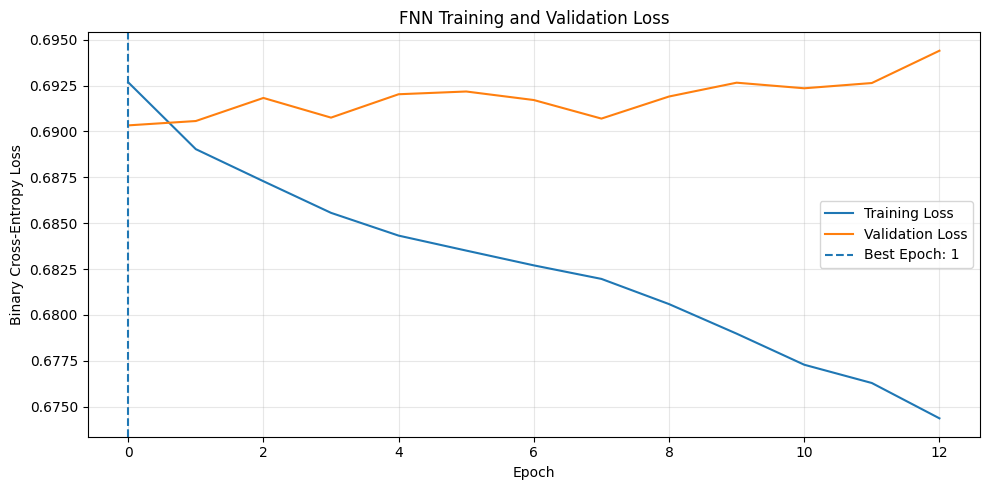

In [93]:

plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("FNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 8.8 Validation Performance Evaluation

After training, the restored best model is used to generate predictions on the validation set.

The network produces a logit for each observation. Applying the sigmoid function converts each logit into an estimated probability of an upward market movement:

$$
\hat p_t = \frac{1}{1+e^{-z_t}}.
$$

A classification threshold of 0.5 is used to convert probabilities into binary predictions:

$$
\hat y_t =
\begin{cases}
1, & \hat p_t \geq 0.5,\\
0, & \hat p_t < 0.5.
\end{cases}
$$

The resulting predictions are evaluated using accuracy, precision, recall, and F1-score. A confusion matrix is also examined to identify the types of errors made by the model.

The validation metrics are compared with the baseline results from Section 7. The test set is not used during this stage, preserving its role as an independent final evaluation set.

In [94]:

# Generate validation probabilities and class predictions
fnn_model.eval()

with torch.no_grad():
    val_logits_fnn = fnn_model(
        X_val_tensor.to(device)
    )

    y_val_prob_fnn = torch.sigmoid(
        val_logits_fnn
    ).cpu().numpy()

y_val_pred_fnn = (
    y_val_prob_fnn >= 0.5
).astype(int)

print("FNN Validation Results")
print(
    classification_report(
        y_val,
        y_val_pred_fnn,
        labels=[0, 1],
        target_names=["Down/Unchanged", "Up"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_fnn))


FNN Validation Results
                precision    recall  f1-score   support

Down/Unchanged       0.44      0.02      0.05       284
            Up       0.54      0.97      0.69       330

      accuracy                           0.53       614
     macro avg       0.49      0.50      0.37       614
  weighted avg       0.49      0.53      0.39       614

Confusion Matrix:
[[  7 277]
 [  9 321]]


### 8.9 Comparative Analysis Against Baseline Models

The FNN's validation performance is compared with the majority-class classifier and logistic regression.

All three models use the same validation observations and the same target definition. This makes the comparison more consistent and allows us to examine whether the nonlinear architecture offers an advantage over simpler alternatives.

The results are interpreted using multiple metrics rather than accuracy alone. In particular, the F1-score for the upward class summarizes the balance between precision and recall for identifying upward market movements.

A neural network is not necessarily superior simply because it has more parameters. If the FNN fails to improve meaningfully upon the baselines, this may indicate that the engineered features contain limited predictive information, that the architecture requires further investigation, or that the observed patterns are difficult to generalize.

Any conclusions at this stage are restricted to validation performance and do not establish out-of-sample trading profitability.

                      Model  Accuracy  Precision  Recall  F1-Score
             Majority Class    0.5375     0.5375  1.0000    0.6992
        Logistic Regression    0.5423     0.5472  0.8606    0.6690
Feed-Forward Neural Network    0.5342     0.5368  0.9727    0.6918


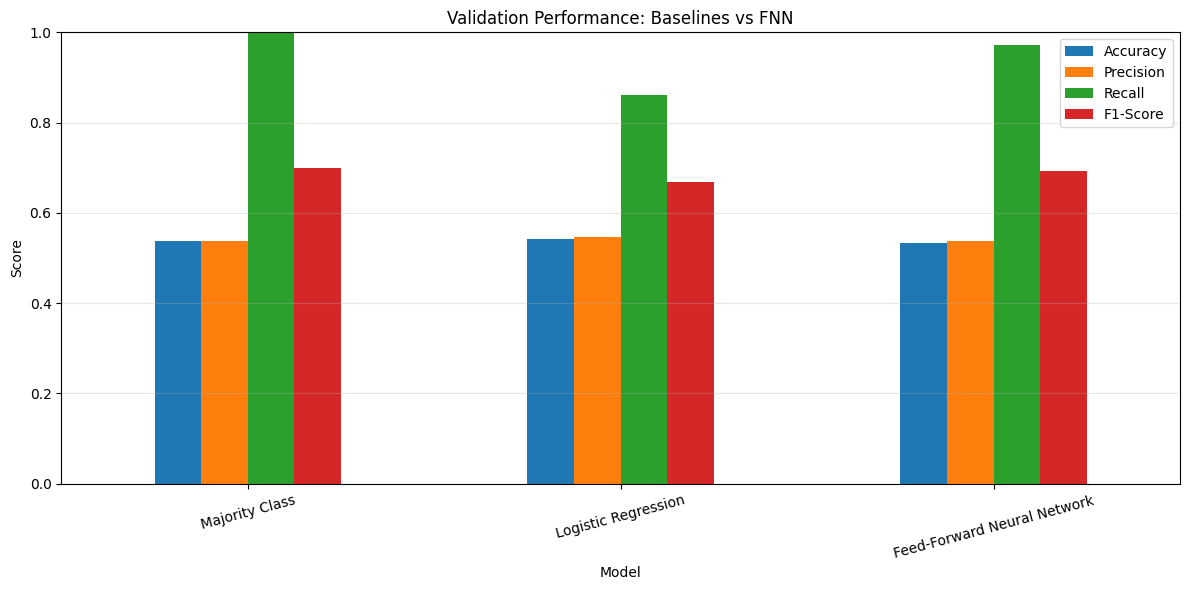

In [95]:

fnn_result = {
    "Model": "Feed-Forward Neural Network",
    "Accuracy": accuracy_score(y_val, y_val_pred_fnn),
    "Precision": precision_score(
        y_val, y_val_pred_fnn, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_fnn, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, y_val_pred_fnn, zero_division=0
    )
}

comparison_results = pd.concat(
    [
        baseline_results,
        pd.DataFrame([fnn_result])
    ],
    ignore_index=True
)

print(
    comparison_results.round(4).to_string(index=False)
)

comparison_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=15
)

plt.title("Validation Performance: Baselines vs FNN")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 8.10 Model Checkpoint and Reproducibility

The trained FNN is saved together with its model configuration and feature-scaling parameters. Saving these components allows the model to be restored later without repeating the entire training process.

The checkpoint includes the neural network's learned parameters, the input dimension, the feature names, and the fitted `StandardScaler`.

The feature order must remain identical during inference because each input position corresponds to a specific engineered feature. The saved scaler must also be reused rather than fitted again on new observations.

This checkpoint provides a reproducible artifact for subsequent analysis and comparison with the LSTM architecture.

In [96]:

checkpoint = {
    "model_state_dict": fnn_model.state_dict(),
    "input_dim": input_dim,
    "feature_columns": feature_columns,
    "scaler_mean": scaler.mean_,
    "scaler_scale": scaler.scale_,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "threshold": 0.5
}

torch.save(
    checkpoint,
    "fnn_market_direction.pt"
)

print("FNN checkpoint saved successfully.")


FNN checkpoint saved successfully.


## 9. Long Short-Term Memory (LSTM) Network

### 9.1 Introduction

Financial time series contain sequential observations whose order may carry information about market behaviour. A conventional feed-forward neural network processes each observation independently, whereas recurrent neural networks maintain a hidden state that is updated as a sequence is processed.

Long Short-Term Memory (LSTM) networks are a specialized type of recurrent neural network designed to learn temporal dependencies while mitigating some of the vanishing-gradient problems associated with conventional recurrent architectures.

In this project, the LSTM receives sequences of engineered features derived from historical NIFTY 50 data. Each sequence represents a fixed number of consecutive trading sessions and is used to predict the direction of the next trading session relative to the final session in that sequence.

The objective is to investigate whether the LSTM's ability to process sequential inputs provides an advantage over the feed-forward neural network and conventional baseline classifiers.

The same engineered features, target definition, chronological evaluation periods, and training-only scaling procedure are retained to make the comparison meaningful. The sequence length and other LSTM hyperparameters are treated as modelling choices rather than assumed to be optimal.

### 9.2 LSTM Architecture and Mathematical Formulation

An LSTM processes a sequence of input vectors while maintaining a hidden state and a cell state. The hidden state represents information exposed to subsequent computations, while the cell state provides a mechanism for retaining information across time steps.

At time step \(t\), let \(\mathbf{x}_t\) denote the input feature vector, \(\mathbf{h}_{t-1}\) the previous hidden state, and \(\mathbf{c}_{t-1}\) the previous cell state.

The LSTM computes three gates and a candidate cell-state update.

**Forget gate**

The forget gate determines how much of the previous cell state should be retained:

$$
\mathbf{f}_t =
\sigma\left(
\mathbf{W}_f[\mathbf{h}_{t-1},\mathbf{x}_t]
+\mathbf{b}_f
\right)
$$

**Input gate**

The input gate controls how much new information is incorporated:

$$
\mathbf{i}_t =
\sigma\left(
\mathbf{W}_i[\mathbf{h}_{t-1},\mathbf{x}_t]
+\mathbf{b}_i
\right)
$$

The candidate cell-state update is

$$
\tilde{\mathbf{c}}_t =
\tanh\left(
\mathbf{W}_c[\mathbf{h}_{t-1},\mathbf{x}_t]
+\mathbf{b}_c
\right)
$$

The cell state is updated according to

$$
\mathbf{c}_t =
\mathbf{f}_t\odot\mathbf{c}_{t-1}
+
\mathbf{i}_t\odot\tilde{\mathbf{c}}_t
$$

where \(\odot\) denotes element-wise multiplication.

**Output gate**

The output gate controls the information exposed through the new hidden state:

$$
\mathbf{o}_t =
\sigma\left(
\mathbf{W}_o[\mathbf{h}_{t-1},\mathbf{x}_t]
+\mathbf{b}_o
\right)
$$

$$
\mathbf{h}_t =
\mathbf{o}_t\odot\tanh(\mathbf{c}_t)
$$

Here, \(\sigma\) denotes the sigmoid function. The gates take values between zero and one, allowing the network to regulate the retention, incorporation, and exposure of information.

### Sequence-Based Prediction

For a sequence of length \(L\), the input is represented as

$$
\mathbf{X}_t =
[\mathbf{x}_{t-L+1},\ldots,\mathbf{x}_t]
$$

The LSTM processes these observations in chronological order. The final hidden state is passed to a linear output layer to obtain a logit for predicting the next-session direction associated with time \(t\).

Using a sequence allows the model to learn temporal representations from multiple consecutive feature vectors. However, the LSTM does not automatically discover profitable market patterns; its performance must be established through chronological validation and testing.

### 9.3 Sequence Construction

An LSTM requires three-dimensional input with the following structure:

$$
(\text{number of samples},\text{sequence length},\text{number of features})
$$

We use a lookback window of 20 trading sessions. Each sample therefore contains 20 consecutive rows of engineered features, with 11 features per session.

For a prediction associated with session \(t\), the sequence contains the feature vectors from sessions \(t-19\) through \(t\). Its target is the direction of session \(t+1\) relative to session \(t\).

The sequence is assigned to a data partition according to its target row, not according to where the sequence begins. Consequently, a validation sequence may use historical feature observations from the training period, and a test sequence may use observations from the preceding validation period. These historical observations would be available at the relevant prediction time.

The scaler is fitted only on the training set, as established in Section 6. It is then applied to all observations using those fixed training statistics before sequences are constructed.

This procedure preserves temporal ordering and avoids unnecessarily discarding the initial observations of the validation and test periods.

In [97]:

# Lookback window: 20 trading sessions
SEQUENCE_LENGTH = 20

# Transform all features using the scaler fitted on training data
# No refitting takes place here.
X_all_scaled = scaler.transform(X)

def create_sequences(X_array, y_array, sequence_length):
    X_sequences = []
    y_sequences = []
    endpoint_positions = []

    for end in range(sequence_length - 1, len(X_array)):
        start = end - sequence_length + 1

        X_sequences.append(
            X_array[start:end + 1]
        )

        y_sequences.append(
            y_array[end]
        )

        endpoint_positions.append(end)

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_sequences, dtype=np.float32),
        np.asarray(endpoint_positions)
    )

X_sequences, y_sequences, sequence_positions = create_sequences(
    X_all_scaled,
    y.to_numpy(),
    SEQUENCE_LENGTH
)

# Identify the partition of each sequence by its target-row index
train_end_position = train_end
val_end_position = val_end

train_mask = sequence_positions < train_end_position

val_mask = (
    (sequence_positions >= train_end_position)
    & (sequence_positions < val_end_position)
)

test_mask = sequence_positions >= val_end_position

X_train_seq = X_sequences[train_mask]
y_train_seq = y_sequences[train_mask]

X_val_seq = X_sequences[val_mask]
y_val_seq = y_sequences[val_mask]

X_test_seq = X_sequences[test_mask]
y_test_seq = y_sequences[test_mask]

print("Training sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Test sequences:", X_test_seq.shape)


Training sequences: (2845, 20, 12)
Validation sequences: (614, 20, 12)
Test sequences: (614, 20, 12)


### 9.4 Conversion to PyTorch Tensors

The sequential feature arrays are converted into PyTorch tensors so that they can be processed by the LSTM.

Each sample has 20 time steps, and each time step contains the 11 engineered features. The target remains a binary floating-point value representing the next-session direction.

A mini-batch training loader is used to train the network. The training sequences may be shuffled at the batch level because each sequence already preserves its internal chronological order. The validation and test sequences retain their original ordering for evaluation.

The validation and test tensors are used only for forward passes and performance assessment, not for gradient updates.

In [98]:

# Convert sequence arrays to tensors
X_train_seq_tensor = torch.tensor(
    X_train_seq, dtype=torch.float32
)
y_train_seq_tensor = torch.tensor(
    y_train_seq, dtype=torch.float32
)

X_val_seq_tensor = torch.tensor(
    X_val_seq, dtype=torch.float32
)
y_val_seq_tensor = torch.tensor(
    y_val_seq, dtype=torch.float32
)

X_test_seq_tensor = torch.tensor(
    X_test_seq, dtype=torch.float32
)
y_test_seq_tensor = torch.tensor(
    y_test_seq, dtype=torch.float32
)

# Create training DataLoader
lstm_train_dataset = TensorDataset(
    X_train_seq_tensor,
    y_train_seq_tensor
)

lstm_train_loader = DataLoader(
    lstm_train_dataset,
    batch_size=64,
    shuffle=True
)

print("LSTM training input:", X_train_seq_tensor.shape)
print("LSTM validation input:", X_val_seq_tensor.shape)
print("LSTM test input:", X_test_seq_tensor.shape)


LSTM training input: torch.Size([2845, 20, 12])
LSTM validation input: torch.Size([614, 20, 12])
LSTM test input: torch.Size([614, 20, 12])


### 9.5 LSTM Model Implementation

The LSTM architecture is implemented using PyTorch's `nn.LSTM` layer.

The network receives sequences with 11 features at each time step. Its hidden state has 64 dimensions, allowing the network to maintain a learned representation of the sequence.

The final hidden representation is passed to a linear layer that produces one logit for binary classification. As with the FNN, the sigmoid transformation is applied only when probabilities are required, while the training loss is calculated directly from logits using `BCEWithLogitsLoss`.

The initial model uses a single LSTM layer. This provides a manageable starting architecture while allowing us to investigate whether sequence modelling improves validation performance relative to the feed-forward network.

In [99]:

class LSTMClassifier(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        num_layers=1,
        dropout=0.0
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x shape: (batch_size, sequence_length, input_dim)
        _, (hidden_state, _) = self.lstm(x)

        # Final layer's final hidden state
        final_hidden = hidden_state[-1]

        # Return one logit per sequence
        return self.output_layer(final_hidden).squeeze(-1)


lstm_model = LSTMClassifier(
    input_dim=X_train_seq_tensor.shape[2],
    hidden_dim=64
).to(device)

print(lstm_model)

print(
    "\nTrainable parameters:",
    sum(
        p.numel()
        for p in lstm_model.parameters()
        if p.requires_grad
    )
)


LSTMClassifier(
  (lstm): LSTM(12, 64, batch_first=True)
  (output_layer): Linear(in_features=64, out_features=1, bias=True)
)

Trainable parameters: 20033


### 9.6 LSTM Training Procedure

The LSTM is trained using binary cross-entropy with logits and the Adam optimizer, following the same general training procedure as the FNN.

During each epoch, the model processes mini-batches of sequences, computes the classification loss, and updates its parameters through backpropagation through time. This allows gradients to influence the recurrent computations across the input sequence.

After each epoch, validation loss is calculated without updating model parameters. The model checkpoint with the lowest validation loss is retained, and early stopping terminates training if validation loss fails to improve for 12 consecutive epochs.

The maximum number of epochs is set to 100, with an initial learning rate of 0.001. These settings provide a starting configuration rather than a claim of optimal hyperparameters.

The validation set guides checkpoint selection, while the test set remains untouched throughout training.

In [100]:

# Reset seeds for reproducibility
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

lstm_criterion = nn.BCEWithLogitsLoss()

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

lstm_history = {
    "train_loss": [],
    "val_loss": []
}

lstm_best_val_loss = float("inf")
lstm_best_epoch = 0
lstm_patience_counter = 0
lstm_best_state = None

for epoch in range(MAX_EPOCHS):

    # Training phase
    lstm_model.train()
    running_loss = 0.0

    for batch_X, batch_y in lstm_train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        lstm_optimizer.zero_grad()

        logits = lstm_model(batch_X)
        loss = lstm_criterion(logits, batch_y)

        loss.backward()
        lstm_optimizer.step()

        running_loss += loss.item() * len(batch_X)

    train_loss = running_loss / len(lstm_train_dataset)

    # Validation phase
    lstm_model.eval()

    with torch.no_grad():
        val_logits = lstm_model(
            X_val_seq_tensor.to(device)
        )

        val_loss = lstm_criterion(
            val_logits,
            y_val_seq_tensor.to(device)
        ).item()

    lstm_history["train_loss"].append(train_loss)
    lstm_history["val_loss"].append(val_loss)

    # Checkpoint selection
    if val_loss < lstm_best_val_loss:
        lstm_best_val_loss = val_loss
        lstm_best_epoch = epoch + 1
        lstm_patience_counter = 0

        lstm_best_state = copy.deepcopy(
            lstm_model.state_dict()
        )
    else:
        lstm_patience_counter += 1

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Validation Loss: {val_loss:.5f}"
        )

    if lstm_patience_counter >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}")
        break

# Restore the best checkpoint
lstm_model.load_state_dict(lstm_best_state)

print("\nBest epoch:", lstm_best_epoch)
print("Best validation loss:", round(lstm_best_val_loss, 5))


Epoch 001 | Train Loss: 0.69073 | Validation Loss: 0.69009
Epoch 010 | Train Loss: 0.68252 | Validation Loss: 0.69318

Early stopping at epoch 13

Best epoch: 1
Best validation loss: 0.69009


### 9.7 Training Dynamics and Overfitting Analysis

The training and validation loss curves are plotted to assess optimization and generalization.

A decreasing training loss indicates that the network is fitting the training sequences more closely. Validation loss indicates whether improvements extend to observations that were not used for parameter updates.

If training loss continues to decrease while validation loss increases, the model may be overfitting. The best checkpoint is selected using the minimum validation loss rather than the lowest training loss.

The comparison of these curves helps assess whether the sequence model has learned a useful representation or whether additional complexity has simply improved its fit to historical observations.

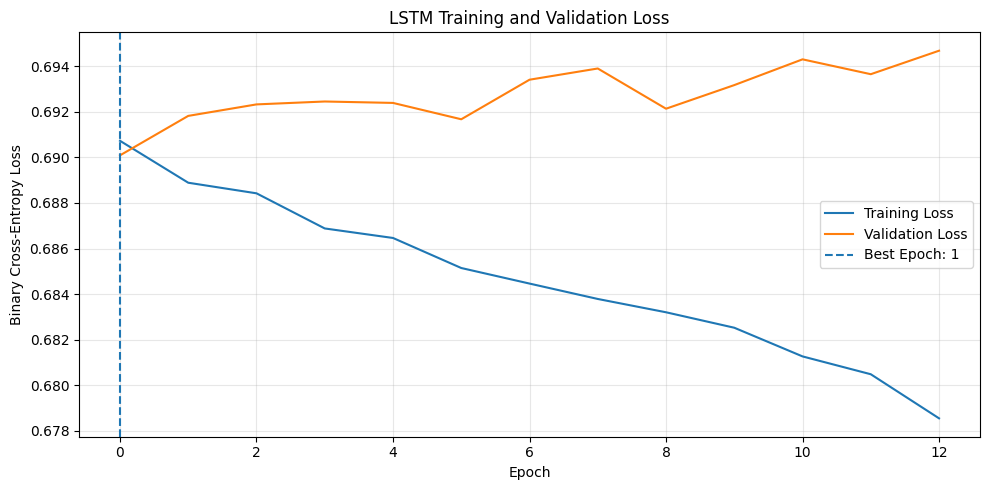

In [101]:

plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    lstm_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    lstm_best_epoch - 1,
    linestyle="--",
    label=f"Best Epoch: {lstm_best_epoch}"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 9.8 Validation Performance Evaluation

After training, the LSTM checkpoint with the lowest validation loss is used to generate predictions on the validation sequences.

The output logits are converted into probabilities using the sigmoid function. A threshold of 0.5 is used to assign each observation to the upward or flat/downward class.

Accuracy, precision, recall, and F1-score are calculated, and a confusion matrix is generated to examine the classification errors.

These results are compared with the FNN and baseline classifiers. Since the sequence targets correspond to the same validation observations as the tabular models, the comparison can assess whether the LSTM's sequential representation offers an advantage.

Performance differences must be interpreted cautiously. A better validation score does not establish that the model will remain effective in future market conditions or generate profitable trades.

In [102]:

# Confirm that the LSTM and FNN validation targets are aligned
assert np.array_equal(
    y_val_seq.astype(int),
    y_val.to_numpy().astype(int)
)

lstm_model.eval()

with torch.no_grad():
    val_logits_lstm = lstm_model(
        X_val_seq_tensor.to(device)
    )

    y_val_prob_lstm = torch.sigmoid(
        val_logits_lstm
    ).cpu().numpy()

y_val_pred_lstm = (
    y_val_prob_lstm >= 0.5
).astype(int)

print("LSTM Validation Results")

print(
    classification_report(
        y_val,
        y_val_pred_lstm,
        labels=[0, 1],
        target_names=["Down/Unchanged", "Up"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_lstm))


LSTM Validation Results
                precision    recall  f1-score   support

Down/Unchanged       0.00      0.00      0.00       284
            Up       0.54      1.00      0.70       330

      accuracy                           0.54       614
     macro avg       0.27      0.50      0.35       614
  weighted avg       0.29      0.54      0.38       614

Confusion Matrix:
[[  0 284]
 [  1 329]]


### 9.9 Comparative Analysis of Baseline and Neural Network Models

The LSTM is compared against the majority-class classifier, logistic regression, and the feed-forward neural network using validation data.

All models are evaluated on the same target observations and use the same classification threshold of 0.5 for their class predictions.

The comparison includes accuracy, precision, recall, and F1-score. These metrics provide a broader view of predictive performance than accuracy alone.

The FNN learns nonlinear relationships from an individual feature vector, whereas the LSTM processes a sequence of feature vectors. Comparing their results helps investigate whether explicit sequential modelling provides additional predictive information for next-session market direction.

The model with the best validation performance is not automatically assumed to be the best final model. Selection should consider the chosen metric, stability, complexity, and evidence of overfitting. The test set remains reserved for the final evaluation after model selection.

                      Model  Accuracy  Precision  Recall  F1-Score
             Majority Class    0.5375     0.5375  1.0000    0.6992
        Logistic Regression    0.5423     0.5472  0.8606    0.6690
Feed-Forward Neural Network    0.5342     0.5368  0.9727    0.6918
                       LSTM    0.5358     0.5367  0.9970    0.6978


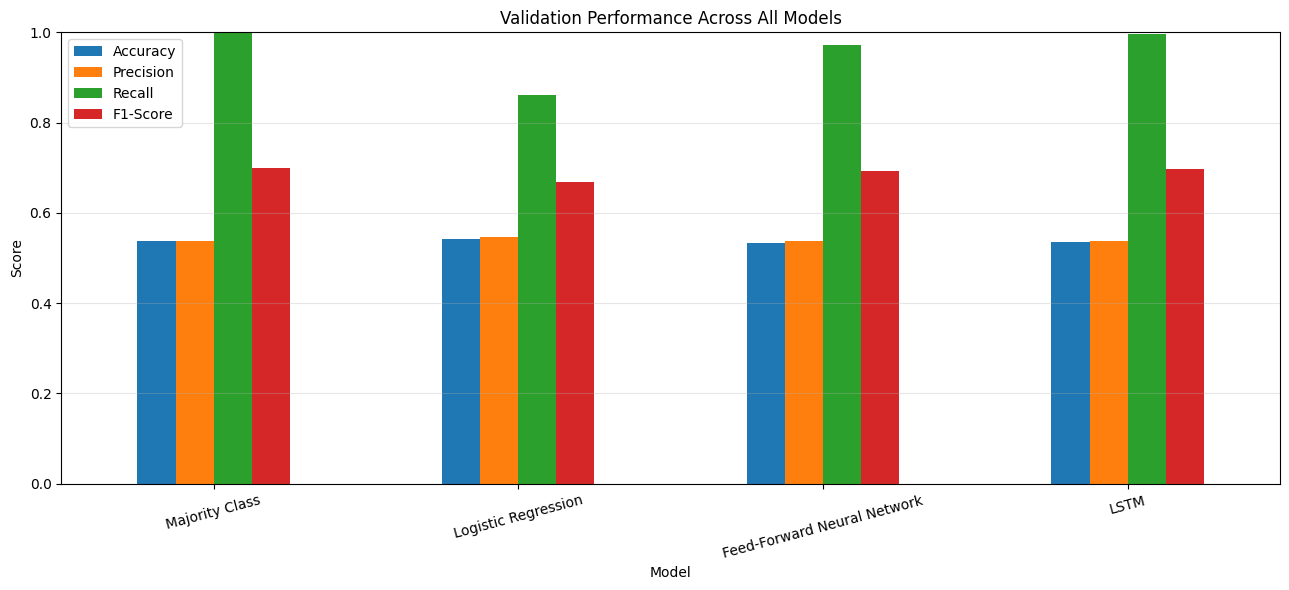

In [103]:

lstm_result = {
    "Model": "LSTM",
    "Accuracy": accuracy_score(y_val, y_val_pred_lstm),
    "Precision": precision_score(
        y_val, y_val_pred_lstm, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_pred_lstm, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, y_val_pred_lstm, zero_division=0
    )
}

# Add the LSTM to the baseline and FNN results
all_model_results = pd.concat(
    [
        comparison_results,
        pd.DataFrame([lstm_result])
    ],
    ignore_index=True
)

print(all_model_results.round(4).to_string(index=False))

all_model_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1),
    rot=15
)

plt.title("Validation Performance Across All Models")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 9.10 Model Checkpoint and Reproducibility

The trained LSTM is saved with its learned parameters, architecture configuration, feature names, sequence length, and fitted feature-scaling statistics.

Saving these components makes it possible to restore the model and reproduce predictions later without retraining it from scratch.

The sequence length and feature ordering must remain consistent during inference. The same scaler fitted on the training set must be reused for new observations.

The saved checkpoint is a reproducible modelling artifact and can be used for subsequent model comparison and final evaluation.

In [104]:

lstm_checkpoint = {
    "model_state_dict": lstm_model.state_dict(),
    "input_dim": X_train_seq_tensor.shape[2],
    "hidden_dim": 64,
    "num_layers": 1,
    "sequence_length": SEQUENCE_LENGTH,
    "feature_columns": feature_columns,
    "scaler_mean": scaler.mean_,
    "scaler_scale": scaler.scale_,
    "best_epoch": lstm_best_epoch,
    "best_val_loss": lstm_best_val_loss,
    "threshold": 0.5
}

torch.save(
    lstm_checkpoint,
    "lstm_market_direction.pt"
)

print("LSTM checkpoint saved successfully.")


LSTM checkpoint saved successfully.


## 10. Final Test Evaluation and Robustness Analysis

### 10.1 Objective

The purpose of this section is to evaluate the generalization performance of the baseline classifiers, feed-forward neural network, and LSTM on the chronologically held-out test period.

The training set was used to estimate model parameters, while the validation set was used for model monitoring and checkpoint selection. The test set has been reserved for the final evaluation.

The analysis includes:

- Accuracy, precision, recall, and F1-score.
- Confusion matrices for the competing models.
- Comparison against the majority-class and logistic regression baselines.
- Examination of prediction probabilities and classification errors.
- Additional robustness checks to understand how performance may vary across market conditions.

The results will be interpreted as evidence about historical classification performance, not as proof of future profitability. A classifier that predicts market direction accurately does not necessarily generate profitable trades after transaction costs, slippage, and risk are considered.

### 10.2 Evaluation Protocol

The selected model checkpoints and preprocessing parameters must remain fixed during final evaluation. No parameters will be fitted using test observations, and test results will not be used to select a new model.

All models will be evaluated on the same test dates, with identical target definitions and classification thresholds. This ensures that differences in measured performance can be compared consistently.

The final test metrics will provide an estimate of performance on this particular unseen historical period. Since financial markets change over time, this estimate should not be interpreted as a guarantee of future performance.

### 10.3 Test-Set Predictions

Each trained model generates predictions for the held-out test observations.

For logistic regression, the fitted classifier estimates the probability of an upward movement using the scaled feature vector. The majority-class classifier predicts the dominant class learned from the training set. The FNN generates logits from individual feature vectors, while the LSTM generates logits from sequences of 20 consecutive feature vectors.

For the neural networks, the sigmoid function converts logits into estimated upward-movement probabilities. A threshold of 0.5 is then applied to obtain binary predictions.

The predictions are generated in evaluation mode without gradient updates. The models, fitted scaler, feature definitions, and classification threshold remain unchanged throughout this evaluation.

In [105]:

# Confirm that the LSTM test targets align with the tabular test targets
assert np.array_equal(
    y_test_seq.astype(int),
    y_test.to_numpy().astype(int)
)

# 1. Majority-class baseline
y_test_pred_majority = majority_model.predict(X_test_scaled)

# 2. Logistic regression
y_test_pred_logistic = logistic_model.predict(X_test_scaled)
y_test_prob_logistic = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

# 3. Feed-forward neural network
fnn_model.eval()

with torch.no_grad():
    test_logits_fnn = fnn_model(
        X_test_tensor.to(device)
    )

    y_test_prob_fnn = torch.sigmoid(
        test_logits_fnn
    ).cpu().numpy()

y_test_pred_fnn = (y_test_prob_fnn >= 0.5).astype(int)

# 4. LSTM
lstm_model.eval()

with torch.no_grad():
    test_logits_lstm = lstm_model(
        X_test_seq_tensor.to(device)
    )

    y_test_prob_lstm = torch.sigmoid(
        test_logits_lstm
    ).cpu().numpy()

y_test_pred_lstm = (y_test_prob_lstm >= 0.5).astype(int)

print("Test observations:", len(y_test))
print("Majority predictions:", len(y_test_pred_majority))
print("Logistic regression predictions:", len(y_test_pred_logistic))
print("FNN predictions:", len(y_test_pred_fnn))
print("LSTM predictions:", len(y_test_pred_lstm))


Test observations: 614
Majority predictions: 614
Logistic regression predictions: 614
FNN predictions: 614
LSTM predictions: 614


### 10.4 Quantitative Performance Comparison

The test predictions are evaluated using accuracy, precision, recall, and F1-score.

Accuracy measures overall correctness. Precision measures how often predicted upward movements are correct, while recall measures how many actual upward movements are identified. The F1-score summarizes the balance between precision and recall.

The positive class is defined as an upward market movement. Precision, recall, and F1-score are therefore calculated for class 1, while the classification report can provide additional per-class information.

All four models are evaluated on the same test observations. The results are compared with the corresponding validation metrics to investigate whether the selected models generalize beyond the period used for model selection.

No single metric is sufficient to establish model quality. The results should be interpreted alongside class frequencies, confusion matrices, and the stability of performance across different periods.

In [106]:

test_predictions = {
    "Majority Class": y_test_pred_majority,
    "Logistic Regression": y_test_pred_logistic,
    "FNN": y_test_pred_fnn,
    "LSTM": y_test_pred_lstm
}

test_results = []

for model_name, predictions in test_predictions.items():
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

test_results = pd.DataFrame(test_results)

print("Final Test-Set Results")
print(test_results.round(4).to_string(index=False))


Final Test-Set Results
              Model  Accuracy  Precision  Recall  F1-Score
     Majority Class    0.5049     0.5049  1.0000    0.6710
Logistic Regression    0.4658     0.4817  0.7645    0.5910
                FNN    0.4984     0.5017  0.9581    0.6585
               LSTM    0.5065     0.5057  1.0000    0.6717


### 10.5 Detailed Error Analysis

Aggregate metrics summarize model performance, but they do not reveal every type of prediction error.

A confusion matrix separates correct upward predictions, correct flat/downward predictions, false upward predictions, and missed upward movements. Examining these outcomes helps determine whether a model favours one class or makes a more balanced set of predictions.

The classification report additionally provides per-class precision, recall, and F1-score, along with macro and weighted averages.

These diagnostics are particularly important when the class distribution is imbalanced. A model may achieve reasonable accuracy while performing poorly on one class, which would limit the usefulness of its predictions.

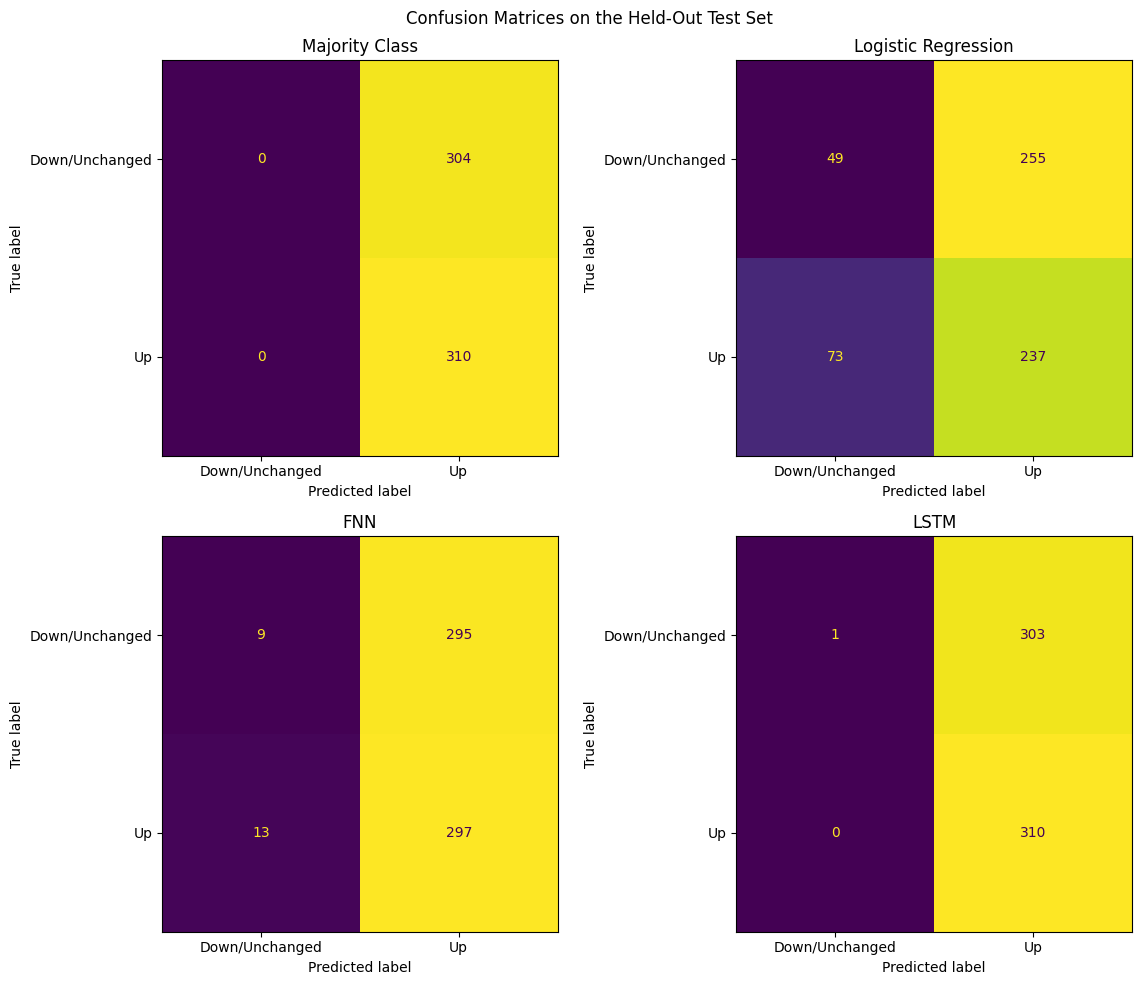


Majority Class
                precision    recall  f1-score   support

Down/Unchanged       0.00      0.00      0.00       304
            Up       0.50      1.00      0.67       310

      accuracy                           0.50       614
     macro avg       0.25      0.50      0.34       614
  weighted avg       0.25      0.50      0.34       614


Logistic Regression
                precision    recall  f1-score   support

Down/Unchanged       0.40      0.16      0.23       304
            Up       0.48      0.76      0.59       310

      accuracy                           0.47       614
     macro avg       0.44      0.46      0.41       614
  weighted avg       0.44      0.47      0.41       614


FNN
                precision    recall  f1-score   support

Down/Unchanged       0.41      0.03      0.06       304
            Up       0.50      0.96      0.66       310

      accuracy                           0.50       614
     macro avg       0.46      0.49      0.36       61

In [107]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, predictions) in zip(
    axes.ravel(), test_predictions.items()
):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Down/Unchanged", "Up"]
    )

    display.plot(ax=ax, colorbar=False)
    ax.set_title(model_name)

plt.suptitle("Confusion Matrices on the Held-Out Test Set")
plt.tight_layout()
plt.show()

for model_name, predictions in test_predictions.items():
    print(f"\n{'=' * 60}")
    print(model_name)
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Down/Unchanged", "Up"],
            zero_division=0
        )
    )


### 10.6 Comparative Visualization

The final test metrics are visualized to facilitate comparison between the baseline classifiers and neural network architectures.

The visualization highlights differences in overall accuracy, positive-class precision, positive-class recall, and F1-score. It helps identify whether improvements in one metric are accompanied by declines in another.

The most complex architecture is not automatically the best model. If an FNN or LSTM performs similarly to logistic regression, the simpler model may be preferable because it is easier to interpret and computationally cheaper.

Model selection should reflect the project's evaluation objectives and the observed evidence rather than an expectation that deep learning must outperform conventional methods.

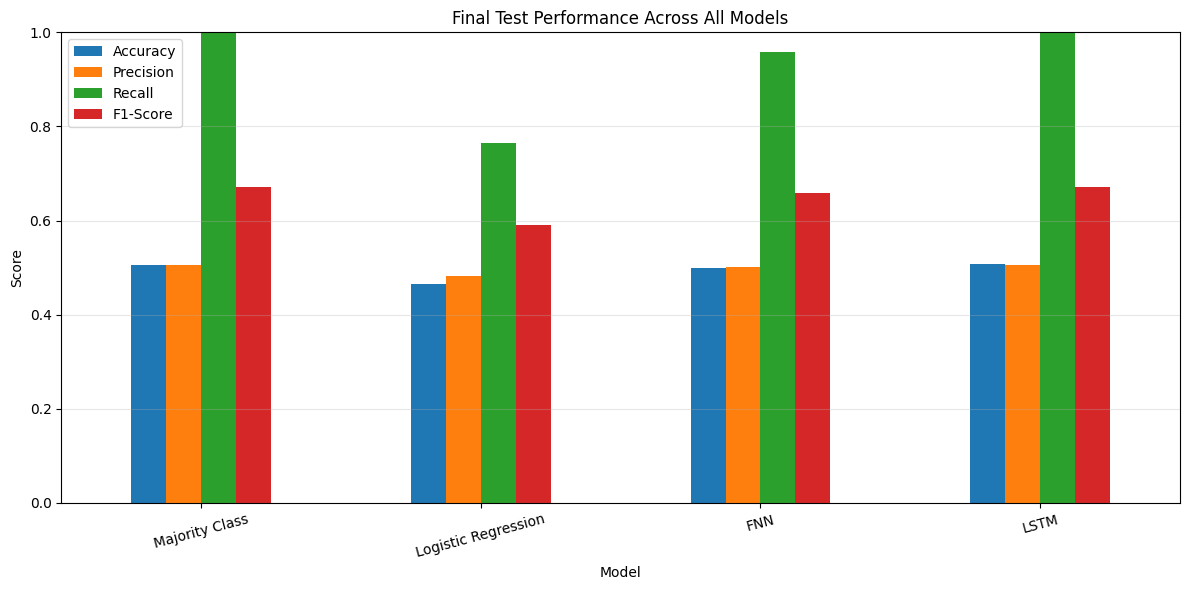

In [108]:

test_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=15
)

plt.title("Final Test Performance Across All Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 10.7 Generalization Analysis

Validation performance measures how models performed on observations used for model selection, whereas test performance measures their predictions on a later, held-out period.

A substantial decline in performance between validation and test periods may indicate overfitting to the validation period, changes in market behaviour, or ordinary sampling variability. Similar performance across both periods provides more consistent evidence of generalization, although it does not guarantee future success.

The validation and test metrics are therefore compared for each model. Differences should be interpreted in the context of their evaluation periods and the underlying market conditions rather than treated as definitive proof of a particular cause.

In [109]:

validation_predictions = {
    "Majority Class": y_val_pred_majority,
    "Logistic Regression": y_val_pred_logistic,
    "FNN": y_val_pred_fnn,
    "LSTM": y_val_pred_lstm
}

validation_summary = []

for model_name, predictions in validation_predictions.items():
    validation_summary.append({
        "Model": model_name,
        "Validation Accuracy": accuracy_score(y_val, predictions),
        "Validation F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

validation_summary = pd.DataFrame(validation_summary)

generalization_results = validation_summary.merge(
    test_results[["Model", "Accuracy", "F1-Score"]],
    on="Model"
).rename(columns={
    "Accuracy": "Test Accuracy",
    "F1-Score": "Test F1"
})

print(generalization_results.round(4).to_string(index=False))


              Model  Validation Accuracy  Validation F1  Test Accuracy  Test F1
     Majority Class               0.5375         0.6992         0.5049   0.6710
Logistic Regression               0.5423         0.6690         0.4658   0.5910
                FNN               0.5342         0.6918         0.4984   0.6585
               LSTM               0.5358         0.6978         0.5065   0.6717


### 10.8 Temporal Robustness Analysis

A single aggregate test score can conceal differences in performance across market conditions. A model may perform well during one portion of the test period and poorly during another.

To investigate this possibility, the test period is divided into three consecutive subwindows. Accuracy and F1-score are calculated separately for each model within each subwindow.

The subwindows are created only for diagnostic analysis. They are not used to retrain models or select new hyperparameters.

Performance variation across these periods may reflect changes in market dynamics, class frequencies, or the limited predictability of daily market direction. Because each subwindow contains fewer observations than the complete test set, its metrics may also be more variable.

This analysis provides an initial robustness check, rather than a substitute for a comprehensive walk-forward evaluation across multiple historical periods.

In [110]:

# Split the held-out test period into three consecutive subwindows
n_test = len(y_test)

test_blocks = np.array_split(
    np.arange(n_test), 3
)

subwindow_results = []

for block_number, positions in enumerate(test_blocks, start=1):
    y_block = y_test.iloc[positions]

    for model_name, predictions in test_predictions.items():
        pred_block = predictions[positions]

        subwindow_results.append({
            "Subwindow": f"Period {block_number}",
            "Model": model_name,
            "Start Date": y_block.index.min(),
            "End Date": y_block.index.max(),
            "Observations": len(y_block),
            "Accuracy": accuracy_score(y_block, pred_block),
            "F1-Score": f1_score(
                y_block, pred_block, zero_division=0
            )
        })

subwindow_results = pd.DataFrame(subwindow_results)

print(
    subwindow_results.round(4).to_string(index=False)
)


Subwindow               Model Start Date   End Date  Observations  Accuracy  F1-Score
 Period 1      Majority Class 2024-04-05 2025-01-31           205    0.5317    0.6943
 Period 1 Logistic Regression 2024-04-05 2025-01-31           205    0.4780    0.6022
 Period 1                 FNN 2024-04-05 2025-01-31           205    0.5073    0.6689
 Period 1                LSTM 2024-04-05 2025-01-31           205    0.5366    0.6965
 Period 2      Majority Class 2025-02-01 2025-12-01           205    0.5073    0.6731
 Period 2 Logistic Regression 2025-02-01 2025-12-01           205    0.5268    0.6498
 Period 2                 FNN 2025-02-01 2025-12-01           205    0.5073    0.6689
 Period 2                LSTM 2025-02-01 2025-12-01           205    0.5073    0.6731
 Period 3      Majority Class 2025-12-02 2026-09-29           204    0.4755    0.6445
 Period 3 Logistic Regression 2025-12-02 2026-09-29           204    0.3922    0.5156
 Period 3                 FNN 2025-12-02 2026-09-29   

### 10.9 Analysis of Predicted Probabilities

The neural networks and logistic regression produce estimated probabilities of an upward market movement. These probabilities contain more information than the final binary classifications alone.

For example, predictions near 0.5 indicate that the model assigns similar probabilities to both classes, whereas probabilities closer to zero or one indicate stronger model-assigned preferences for a particular class.

However, a confident prediction is not necessarily a correct prediction. Probability calibration should be examined before interpreting model outputs as reliable estimates of real-world event probabilities.

In this section, the predicted probabilities of the logistic regression, FNN, and LSTM are visualized across the test period. The analysis helps reveal whether the models produce nearly constant probabilities or meaningful variation in their predictions.

The majority-class classifier is excluded from this probability comparison because its predictions do not provide a useful continuous probability series for this analysis.

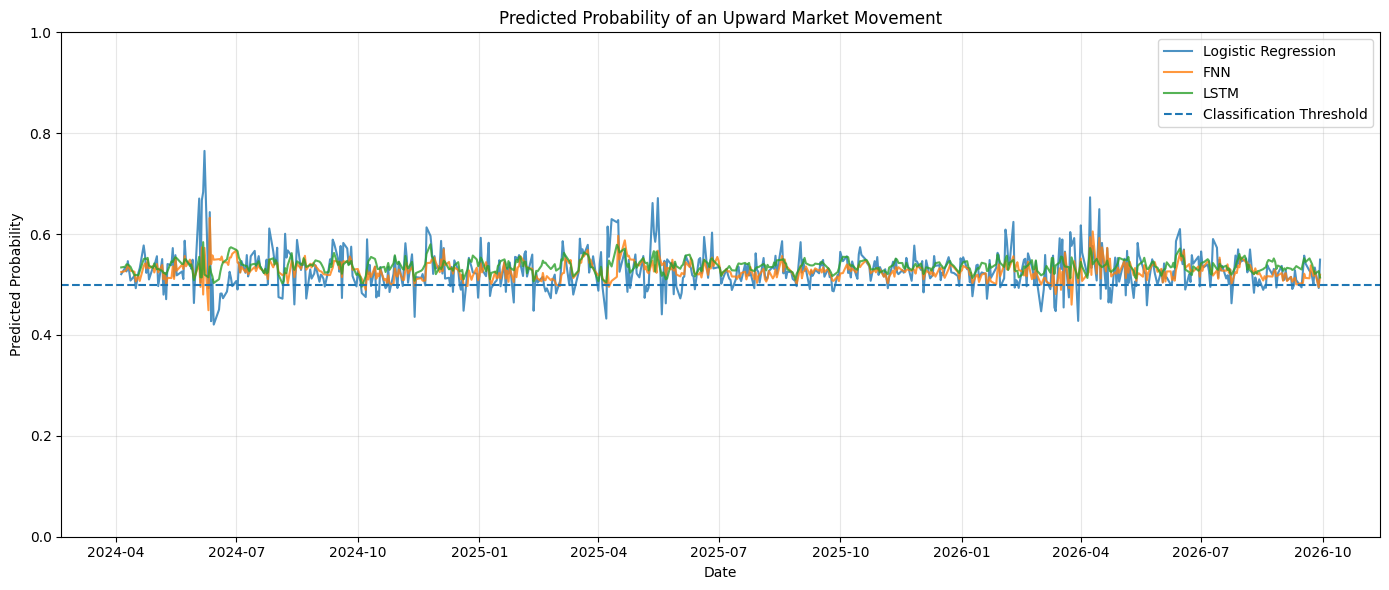

In [111]:

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test_prob_logistic,
    label="Logistic Regression",
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_test_prob_fnn,
    label="FNN",
    alpha=0.8
)

plt.plot(
    y_test.index,
    y_test_prob_lstm,
    label="LSTM",
    alpha=0.8
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Classification Threshold"
)

plt.title("Predicted Probability of an Upward Market Movement")
plt.xlabel("Date")
plt.ylabel("Predicted Probability")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 10.10 Summary and Interpretation

This section evaluated the baseline classifiers, feed-forward neural network, and LSTM on the chronologically held-out test set. The analysis considered classification metrics, confusion matrices, validation-to-test performance differences, and performance variation across test-period subwindows.

The main conclusions should be based on the measured results:

- Whether the neural networks outperform the majority-class baseline.
- Whether nonlinear or sequential modelling improves upon logistic regression.
- Whether performance remains reasonably consistent between validation and test periods.
- Whether errors are concentrated in a particular market-direction class.
- Whether performance varies substantially across test-period subwindows.

The observed results apply to the selected market, features, prediction horizon, and historical evaluation period. They should not be generalized automatically to other assets or future market conditions.

Finally, directional classification performance does not establish trading profitability. A separate trading-strategy evaluation would be required to account for position sizing, transaction costs, slippage, turnover, and risk-adjusted returns.

The project therefore distinguishes between the ability to classify historical market direction and the separate question of whether the resulting predictions can support a viable trading strategy.

In [112]:

# Identify the models with the highest observed test metrics
best_accuracy_row = test_results.loc[
    test_results["Accuracy"].idxmax()
]

best_f1_row = test_results.loc[
    test_results["F1-Score"].idxmax()
]

print("FINAL TEST SUMMARY")
print("-" * 50)

print(
    f"Highest test accuracy: {best_accuracy_row['Model']} "
    f"({best_accuracy_row['Accuracy']:.4f})"
)

print(
    f"Highest test F1-score: {best_f1_row['Model']} "
    f"({best_f1_row['F1-Score']:.4f})"
)

print("\nComplete test metrics:")
print(test_results.round(4).to_string(index=False))


FINAL TEST SUMMARY
--------------------------------------------------
Highest test accuracy: LSTM (0.5065)
Highest test F1-score: LSTM (0.6717)

Complete test metrics:
              Model  Accuracy  Precision  Recall  F1-Score
     Majority Class    0.5049     0.5049  1.0000    0.6710
Logistic Regression    0.4658     0.4817  0.7645    0.5910
                FNN    0.4984     0.5017  0.9581    0.6585
               LSTM    0.5065     0.5057  1.0000    0.6717


## 11. Walk-Forward Validation and Statistical Robustness

### 11.1 Motivation

A single train-validation-test split provides an estimate of model performance over one particular historical period. However, financial markets exhibit changing volatility, trends, and market conditions, so a model's performance may vary substantially across time.

Walk-forward validation addresses this limitation by repeatedly training a model on historical observations and evaluating it on a subsequent, chronologically later period.

For each evaluation window:

1. A training period containing only past observations is selected.
2. The model and preprocessing parameters are fitted using that training period.
3. The fitted model predicts a subsequent validation window.
4. The evaluation window advances forward in time, and the process is repeated.

The general ordering is

$$
D_{\text{train}}^{(k)}
\prec D_{\text{eval}}^{(k)}
$$

where \(k\) indexes the evaluation window.

This procedure better reflects the chronological nature of financial forecasting and helps identify whether predictive performance is concentrated in a particular period.

In this section, walk-forward validation is first implemented for logistic regression, providing a computationally efficient baseline for repeated historical evaluation. Each fold uses its own training-fitted scaler and classifier. The previously reserved final test period is excluded from this analysis.

The results are interpreted across evaluation windows rather than relying on a single aggregate score. Consistent performance across multiple periods provides stronger evidence of robustness, although it does not guarantee future predictive success.

### 11.2 Expanding-Window Validation Design

We use an expanding-window design, in which the training set grows as evaluation advances through time.

The earliest observations form the initial training window. Each subsequent fold evaluates the model on a later block of observations, while observations from earlier evaluation periods become available for training in subsequent folds.

Unlike random cross-validation, this procedure preserves temporal order and prevents a model from training on observations that occur after its evaluation period.

The experiment uses five chronological folds. The feature matrix and target vector are taken from the pre-test development period, consisting of the original training and validation subsets. The final test observations remain excluded.

Within every fold, standardization is fitted exclusively on the fold's training observations. Logistic regression is then fitted using the standardized training data and evaluated on the following observations.

The fold-level metrics provide a view of how predictive performance changes across historical periods. Because adjacent evaluation windows may share similar market conditions, the folds should not be treated as statistically independent experiments.

In [113]:

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline

# Use only the pre-test development period.
# The final test period remains untouched.
X_development = X.iloc[:val_end].copy()
y_development = y.iloc[:val_end].copy()

# Define expanding-window chronological folds
tscv = TimeSeriesSplit(n_splits=5)

walk_forward_results = []

for fold, (train_idx, eval_idx) in enumerate(
    tscv.split(X_development), start=1
):
    X_fold_train = X_development.iloc[train_idx]
    y_fold_train = y_development.iloc[train_idx]

    X_fold_eval = X_development.iloc[eval_idx]
    y_fold_eval = y_development.iloc[eval_idx]

    # Scaling is fitted only on this fold's training data
    fold_model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    fold_model.fit(X_fold_train, y_fold_train)
    fold_predictions = fold_model.predict(X_fold_eval)

    walk_forward_results.append({
        "Fold": fold,
        "Train Start": X_fold_train.index.min(),
        "Train End": X_fold_train.index.max(),
        "Eval Start": X_fold_eval.index.min(),
        "Eval End": X_fold_eval.index.max(),
        "Train Size": len(train_idx),
        "Eval Size": len(eval_idx),
        "Accuracy": accuracy_score(
            y_fold_eval, fold_predictions
        ),
        "Precision": precision_score(
            y_fold_eval, fold_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_fold_eval, fold_predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_fold_eval, fold_predictions,
            zero_division=0
        )
    })

walk_forward_results = pd.DataFrame(walk_forward_results)

print(walk_forward_results.round(4).to_string(index=False))


 Fold Train Start  Train End Eval Start   Eval End  Train Size  Eval Size  Accuracy  Precision  Recall  F1-Score
    1  2010-02-02 2012-06-14 2012-06-15 2014-11-03         583        579    0.5233     0.5683  0.4920    0.5274
    2  2010-02-02 2014-11-03 2014-11-05 2017-03-17        1162        579    0.5112     0.5214  0.6900    0.5940
    3  2010-02-02 2017-03-17 2017-03-20 2019-07-25        1741        579    0.5320     0.5444  0.7370    0.6262
    4  2010-02-02 2019-07-25 2019-07-26 2021-12-01        2320        579    0.5544     0.5920  0.7169    0.6485
    5  2010-02-02 2021-12-01 2021-12-02 2024-04-04        2899        579    0.5492     0.5540  0.8662    0.6758


### 11.3 Fold-Level Performance Analysis

The walk-forward results are examined to determine whether the classifier's performance remains stable across evaluation windows.

For each fold, we record accuracy, precision, recall, and F1-score. We then calculate the mean and standard deviation of these metrics across the five folds.

The mean provides a summary of average performance across the evaluation windows, while the standard deviation describes the degree of variation between them.

A low standard deviation may indicate relatively consistent performance across the selected periods, whereas a high standard deviation suggests that predictive quality varies with time. However, neither statistic alone establishes that a model has genuine predictive power.

These summaries must also be interpreted alongside the class distributions and sample sizes of individual folds. In particular, precision and recall may vary substantially when the number of observations in a class is small.

In [114]:

walk_forward_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

fold_summary = pd.DataFrame({
    "Mean": walk_forward_results[
        walk_forward_metrics
    ].mean(),

    "Standard Deviation": walk_forward_results[
        walk_forward_metrics
    ].std(),

    "Minimum": walk_forward_results[
        walk_forward_metrics
    ].min(),

    "Maximum": walk_forward_results[
        walk_forward_metrics
    ].max()
})

print("Walk-Forward Performance Summary")
print(fold_summary.round(4))


Walk-Forward Performance Summary
             Mean  Standard Deviation  Minimum  Maximum
Accuracy   0.5340              0.0179   0.5112   0.5544
Precision  0.5560              0.0264   0.5214   0.5920
Recall     0.7004              0.1348   0.4920   0.8662
F1-Score   0.6144              0.0571   0.5274   0.6758


### 11.4 Visualization of Walk-Forward Performance

Plotting the metrics across successive folds makes temporal changes in predictive performance easier to identify.

If accuracy and F1-score fluctuate considerably across evaluation windows, the model may be sensitive to changes in market conditions. Conversely, relatively stable metrics indicate that performance is more consistent across the historical periods examined.

This visualization helps distinguish a model that performs well only during one particular window from a model that achieves similar results across several windows.

The analysis remains descriptive. Five evaluation folds provide useful initial evidence but are not sufficient to establish universal robustness across all market environments.

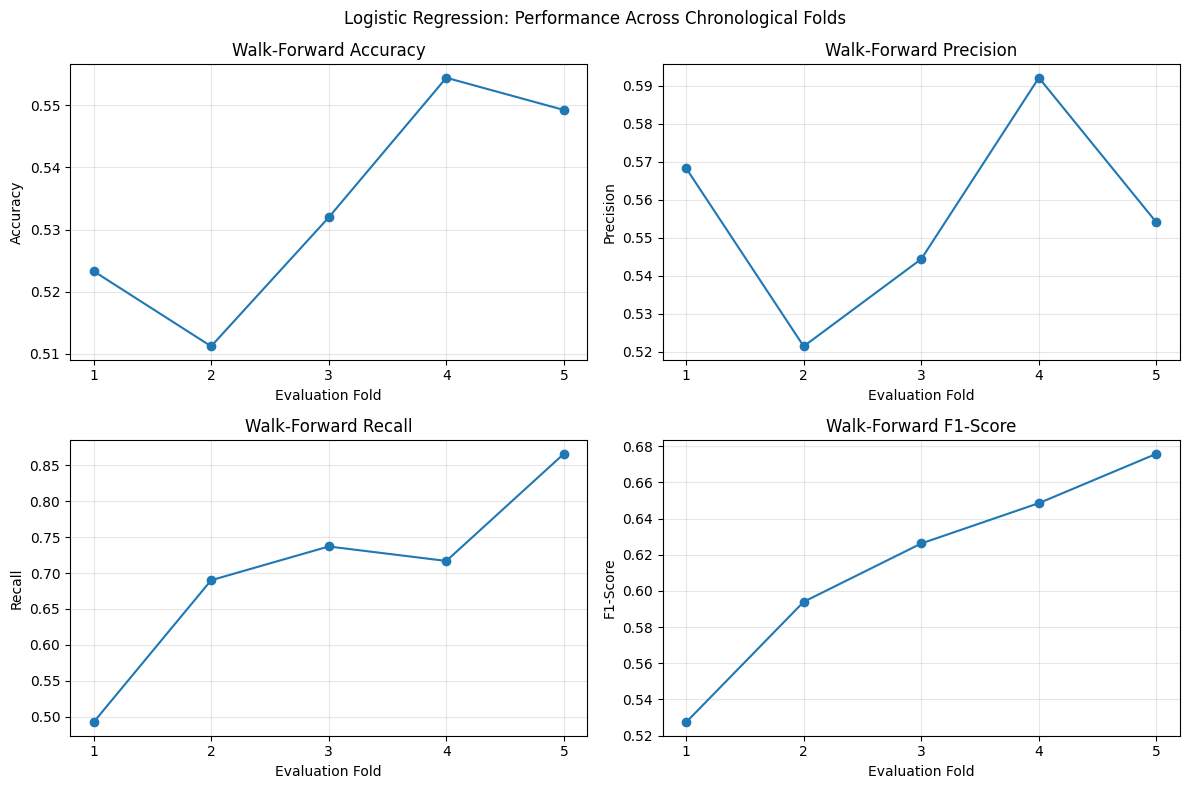

In [115]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric in zip(
    axes.ravel(), walk_forward_metrics
):
    ax.plot(
        walk_forward_results["Fold"],
        walk_forward_results[metric],
        marker="o"
    )

    ax.set_title(f"Walk-Forward {metric}")
    ax.set_xlabel("Evaluation Fold")
    ax.set_ylabel(metric)
    ax.set_xticks(walk_forward_results["Fold"])
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Logistic Regression: Performance Across Chronological Folds"
)
plt.tight_layout()
plt.show()


### 11.5 Fold-Specific Majority-Class Benchmark

The majority-class baseline is recalculated independently for each fold using only that fold's training labels.

This is important because the dominant market direction can change over time. A majority-class classifier fitted on the complete dataset would use information unavailable at earlier evaluation dates and would therefore be an invalid benchmark for walk-forward analysis.

For every fold, the baseline predicts the most frequent class in the training period for all observations in the subsequent evaluation window. Its performance is then compared with logistic regression on exactly the same evaluation observations.

This comparison determines whether logistic regression provides an improvement over a simple prediction rule across multiple historical periods rather than only on one validation split.

In [116]:

majority_walk_forward = []

for fold, (train_idx, eval_idx) in enumerate(
    tscv.split(X_development), start=1
):
    y_fold_train = y_development.iloc[train_idx]
    y_fold_eval = y_development.iloc[eval_idx]

    # Learn the majority class from this fold's training labels
    majority_class = y_fold_train.mode().iloc[0]

    baseline_predictions = np.full(
        len(eval_idx),
        majority_class,
        dtype=int
    )

    majority_walk_forward.append({
        "Fold": fold,
        "Accuracy": accuracy_score(
            y_fold_eval, baseline_predictions
        ),
        "F1-Score": f1_score(
            y_fold_eval,
            baseline_predictions,
            zero_division=0
        )
    })

majority_walk_forward = pd.DataFrame(
    majority_walk_forward
)

walk_forward_comparison = walk_forward_results[
    ["Fold", "Accuracy", "F1-Score"]
].merge(
    majority_walk_forward,
    on="Fold",
    suffixes=("_Logistic", "_Majority")
)

print(walk_forward_comparison.round(4).to_string(index=False))


 Fold  Accuracy_Logistic  F1-Score_Logistic  Accuracy_Majority  F1-Score_Majority
    1             0.5233             0.5274             0.5406             0.7018
    2             0.5112             0.5940             0.5181             0.6826
    3             0.5320             0.6262             0.5320             0.6945
    4             0.5544             0.6485             0.5734             0.7289
    5             0.5492             0.6758             0.5423             0.7032


### 11.6 Discussion and Limitations

Walk-forward validation provides additional evidence about how the logistic regression classifier behaves across different historical periods.

The analysis should address the following questions:

1. Does logistic regression outperform the fold-specific majority-class baseline consistently, or only in selected periods?
2. How much does accuracy vary between evaluation windows?
3. Does the F1-score indicate that the classifier identifies upward movements effectively?
4. Are there periods in which performance deteriorates substantially?
5. Do the results suggest that the engineered features contain useful predictive information, or is the observed performance close to the baseline?

The conclusions must be based on the observed fold-level metrics rather than assumptions about which model should perform best.

### Limitations

This initial walk-forward experiment evaluates logistic regression rather than retraining every neural network across every fold. Consequently, its results establish a robustness benchmark for the conventional classifier but do not establish that the FNN and LSTM are equally robust.

The expanding-window design also uses one particular choice of initial training size and evaluation-window structure. Alternative window lengths, different market periods, and additional assets could produce different results.

Finally, classification metrics do not directly measure financial returns. Any claim about practical trading usefulness would require a separate strategy backtest with realistic transaction costs, slippage, position sizing, and risk evaluation.

Overall, walk-forward validation strengthens the experimental methodology by examining performance across multiple chronological periods instead of relying exclusively on a single train-validation-test split.

In [117]:

# Summarize the average performance of both approaches
print("Mean walk-forward accuracy")
print(
    "Logistic Regression:",
    round(walk_forward_results["Accuracy"].mean(), 4)
)
print(
    "Majority Baseline:",
    round(majority_walk_forward["Accuracy"].mean(), 4)
)

print("\nMean walk-forward F1-score")
print(
    "Logistic Regression:",
    round(walk_forward_results["F1-Score"].mean(), 4)
)
print(
    "Majority Baseline:",
    round(majority_walk_forward["F1-Score"].mean(), 4)
)

# Count folds in which logistic regression beats the baseline
accuracy_wins = (
    walk_forward_comparison["Accuracy_Logistic"]
    > walk_forward_comparison["Accuracy_Majority"]
).sum()

f1_wins = (
    walk_forward_comparison["F1-Score_Logistic"]
    > walk_forward_comparison["F1-Score_Majority"]
).sum()

print(
    f"\nLogistic regression beats the majority baseline "
    f"in accuracy in {accuracy_wins} out of "
    f"{len(walk_forward_comparison)} folds."
)

print(
    f"Logistic regression beats the majority baseline "
    f"in F1-score in {f1_wins} out of "
    f"{len(walk_forward_comparison)} folds."
)


Mean walk-forward accuracy
Logistic Regression: 0.534
Majority Baseline: 0.5413

Mean walk-forward F1-score
Logistic Regression: 0.6144
Majority Baseline: 0.7022

Logistic regression beats the majority baseline in accuracy in 1 out of 5 folds.
Logistic regression beats the majority baseline in F1-score in 0 out of 5 folds.


## 12. Trading Strategy Backtesting and Financial Performance

### 12.1 Motivation

Classification metrics evaluate whether a model correctly predicts market direction. However, they do not directly measure the financial outcome of acting on those predictions.

A trading strategy converts model outputs into positions in a financial instrument. Its performance depends on prediction quality, position timing, transaction costs, turnover, and exposure to market risk.

This section investigates whether the directional predictions generated by the feed-forward neural network and LSTM can support a simple long-or-cash strategy.

The strategy enters a long position when the predicted probability of an upward market movement reaches a specified threshold. Otherwise, it holds cash. The resulting strategy returns are compared with a buy-and-hold benchmark over the same historical evaluation period.

The analysis considers cumulative returns, annualized volatility, maximum drawdown, the Sharpe ratio, and turnover. Transaction costs are included to illustrate how implementation expenses can affect performance.

The backtest is a research experiment, not a recommendation to trade. Its results depend on the assumed execution timing, threshold, costs, and historical period. No profitability is assumed in advance.

### 12.2 Trading Signal and Position Sizing

The trading strategy uses the predicted probability of an upward market movement to determine its position.

Let \(\hat p_t\) denote the model's estimated probability that the next trading session's closing price will exceed the current closing price. The position is defined as

$$
w_t =
\begin{cases}
1, & \hat p_t \geq \theta,\\
0, & \hat p_t < \theta,
\end{cases}
$$

where \(\theta\) is the probability threshold, initially set to 0.5.

A position of 1 represents full long exposure, while a position of 0 represents holding cash. Short selling and leverage are excluded from this initial experiment.

The signal is generated using information available after the current session closes. The strategy then earns the next close-to-close return, subject to the execution and transaction-cost assumptions described below.

The threshold is fixed before examining the final test results. Selecting a threshold after repeatedly inspecting test performance would introduce selection bias and could produce an overly optimistic backtest.

This simple rule provides a transparent starting point for investigating whether the predicted probabilities have financial value beyond their classification metrics.

In [118]:

# Fixed trading rule parameters
PROBABILITY_THRESHOLD = 0.50

# Illustrative one-way transaction cost: 0.10% per unit of turnover
# This is a modelling assumption, not a verified market fee.
TRANSACTION_COST = 0.001

# Ensure the predictions correspond to the test dates
test_dates = y_test.index

strategy_probabilities = {
    "FNN": pd.Series(
        y_test_prob_fnn,
        index=test_dates
    ),
    "LSTM": pd.Series(
        y_test_prob_lstm,
        index=test_dates
    ),
    "Logistic Regression": pd.Series(
        y_test_prob_logistic,
        index=test_dates
    )
}

# Future close-to-close return for each prediction date
forward_returns = (
    data["Close"].shift(-1) / data["Close"] - 1
).reindex(test_dates)

# Keep only dates with an observed next-session return
valid_dates = forward_returns.dropna().index

forward_returns = forward_returns.loc[valid_dates]

strategy_probabilities = {
    name: probabilities.loc[valid_dates]
    for name, probabilities in strategy_probabilities.items()
}

# Create long-or-cash positions
strategy_positions = {
    name: (probabilities >= PROBABILITY_THRESHOLD).astype(int)
    for name, probabilities in strategy_probabilities.items()
}

print("Backtest observations:", len(valid_dates))
print("Start date:", valid_dates.min())
print("End date:", valid_dates.max())
print("Probability threshold:", PROBABILITY_THRESHOLD)
print("Assumed one-way transaction cost:", TRANSACTION_COST)


Backtest observations: 614
Start date: 2024-04-05 00:00:00
End date: 2026-09-29 00:00:00
Probability threshold: 0.5
Assumed one-way transaction cost: 0.001


### 12.3 Gross and Net Strategy Returns

Let \(r_{t+1}\) denote the market return between the close of session \(t\) and the close of session \(t+1\). The strategy's gross return is

$$
r_{t+1}^{\text{gross}} = w_t r_{t+1}.
$$

When the strategy holds cash, its market return is assumed to be zero. Interest earned on cash is ignored in this initial experiment.

Changing a position generates turnover. For a long-or-cash strategy, turnover is measured by the absolute change in the position:

$$
\tau_t = |w_t-w_{t-1}|.
$$

A transition from cash to long exposure, or from long exposure to cash, therefore generates one unit of turnover. Remaining in the same position generates no additional turnover.

The net return is calculated as

$$
r_{t+1}^{\text{net}}
=
w_t r_{t+1}
-
c|w_t-w_{t-1}|,
$$

where \(c\) represents the assumed one-way transaction cost.

The initial position is assumed to be cash. Thus, entering the first long position incurs a transaction cost, while holding an existing position does not incur another entry cost.

This calculation models transaction costs as a proportional deduction from portfolio returns. It is a simplified approximation that does not explicitly model bid-ask spreads, market impact, taxes, or execution slippage.

In [119]:

strategy_returns = {}

for name, positions in strategy_positions.items():

    # Previous position is cash before the first test observation
    previous_positions = positions.shift(1, fill_value=0)

    # Position changes determine turnover
    turnover = (
        positions - previous_positions
    ).abs()

    gross_returns = positions * forward_returns

    net_returns = (
        gross_returns
        - TRANSACTION_COST * turnover
    )

    strategy_returns[name] = pd.DataFrame({
        "Probability": strategy_probabilities[name],
        "Position": positions,
        "Market_Return": forward_returns,
        "Turnover": turnover,
        "Gross_Return": gross_returns,
        "Net_Return": net_returns
    })

# Buy-and-hold benchmark: remain fully invested
buy_hold = pd.DataFrame(index=valid_dates)

buy_hold["Position"] = 1
buy_hold["Market_Return"] = forward_returns
buy_hold["Turnover"] = 0

buy_hold["Gross_Return"] = forward_returns
buy_hold["Net_Return"] = forward_returns

strategy_returns["Buy and Hold"] = buy_hold

print("FNN strategy preview:")
print(strategy_returns["FNN"].head())

print("\nLSTM strategy preview:")
print(strategy_returns["LSTM"].head())


FNN strategy preview:
            Probability  Position  Market_Return  Turnover  Gross_Return  \
Date                                                                       
2024-04-05     0.524794         1       0.006778         1      0.006778   
2024-04-08     0.526618         1      -0.001039         0     -0.001039   
2024-04-09     0.530014         1       0.004904         0      0.004904   
2024-04-10     0.537758         1      -0.010302         0     -0.010302   
2024-04-12     0.527442         1      -0.010964         0     -0.010964   

            Net_Return  
Date                    
2024-04-05    0.005778  
2024-04-08   -0.001039  
2024-04-09    0.004904  
2024-04-10   -0.010302  
2024-04-12   -0.010964  

LSTM strategy preview:
            Probability  Position  Market_Return  Turnover  Gross_Return  \
Date                                                                       
2024-04-05     0.533912         1       0.006778         1      0.006778   
2024-04-08     0.5

### 12.4 Financial Performance Metrics

The trading strategies are evaluated using metrics that describe cumulative growth, risk, and trading activity.

**Cumulative return** measures the total compounded return over the backtest period:

$$
R_{\text{total}}
=
\prod_{t=1}^{T}(1+r_t)-1.
$$

**Annualized return** estimates the compound growth rate using 252 trading sessions per year:

$$
R_{\text{annual}}
=
\left[\prod_{t=1}^{T}(1+r_t)\right]^{252/T}-1.
$$

**Annualized volatility** measures the dispersion of daily returns, scaled by the square root of 252:

$$
\sigma_{\text{annual}}
=
\sigma_{\text{daily}}\sqrt{252}.
$$

**Sharpe ratio** measures average excess return relative to return volatility. Since the initial backtest assumes a zero risk-free rate, it is calculated as

$$
S =
\frac{\bar r}{\sigma_{\text{daily}}}\sqrt{252}.
$$

**Maximum drawdown** measures the largest peak-to-trough decline in the compounded equity curve.

**Turnover** measures how frequently the strategy changes its exposure. Higher turnover generally increases sensitivity to transaction costs.

These annualized measures are approximations based on daily observations. They should be interpreted cautiously when the evaluation period is short or the return distribution is highly non-normal.

In [120]:

TRADING_DAYS_PER_YEAR = 252

def calculate_performance_metrics(returns, turnover=None):
    returns = pd.Series(returns).dropna()

    if len(returns) == 0:
        return {}

    equity = (1 + returns).cumprod()

    total_return = equity.iloc[-1] - 1

    annualized_return = (
        equity.iloc[-1] ** (
            TRADING_DAYS_PER_YEAR / len(returns)
        ) - 1
        if equity.iloc[-1] > 0
        else np.nan
    )

    daily_volatility = returns.std(ddof=1)

    annualized_volatility = (
        daily_volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
        if pd.notna(daily_volatility)
        else np.nan
    )

    sharpe_ratio = (
        returns.mean() / daily_volatility
        * np.sqrt(TRADING_DAYS_PER_YEAR)
        if pd.notna(daily_volatility) and daily_volatility > 0
        else np.nan
    )

    running_peak = equity.cummax()
    drawdown = equity / running_peak - 1
    max_drawdown = drawdown.min()

    metrics = {
        "Total Return": total_return,
        "Annualized Return": annualized_return,
        "Annualized Volatility": annualized_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown": max_drawdown
    }

    if turnover is not None:
        turnover = pd.Series(turnover).reindex(returns.index)
        metrics["Annualized Turnover"] = (
            turnover.mean() * TRADING_DAYS_PER_YEAR
        )

    return metrics


performance_rows = []

for name, result in strategy_returns.items():
    metrics = calculate_performance_metrics(
        result["Net_Return"],
        result["Turnover"]
    )

    metrics["Strategy"] = name
    performance_rows.append(metrics)

performance_table = pd.DataFrame(performance_rows).set_index(
    "Strategy"
)

print("Net-of-assumed-cost performance")
print(performance_table.round(4).to_string())


Net-of-assumed-cost performance
                     Total Return  Annualized Return  Annualized Volatility  Sharpe Ratio  Maximum Drawdown  Annualized Turnover
Strategy                                                                                                                        
FNN                       -0.1042            -0.0442                 0.1299       -0.2825           -0.1885              16.0065
LSTM                       0.0106             0.0043                 0.1363        0.0999           -0.1519               1.2313
Logistic Regression       -0.3151            -0.1439                 0.1194       -1.2410           -0.3708              75.1075
Buy and Hold               0.0047             0.0019                 0.1365        0.0825           -0.1577               0.0000


### 12.5 Cumulative Equity Curve Comparison

An equity curve represents the growth of an initial investment after successive returns are compounded.

For a strategy with net returns \(r_t^{\text{net}}\), the normalized equity curve is

$$
E_t=\prod_{i=1}^{t}(1+r_i^{\text{net}}).
$$

The initial portfolio value is normalized to 1, allowing the strategies to be compared without specifying a particular investment amount.

The equity curves show how returns accumulate through time and reveal periods of gains, losses, and relative underperformance.

The buy-and-hold benchmark remains exposed to the market throughout the evaluation period, whereas the model-based strategies may switch between long exposure and cash.

The comparison should account for both the final portfolio value and the path taken to reach it. A higher ending value may come with larger drawdowns or greater exposure to adverse market movements.

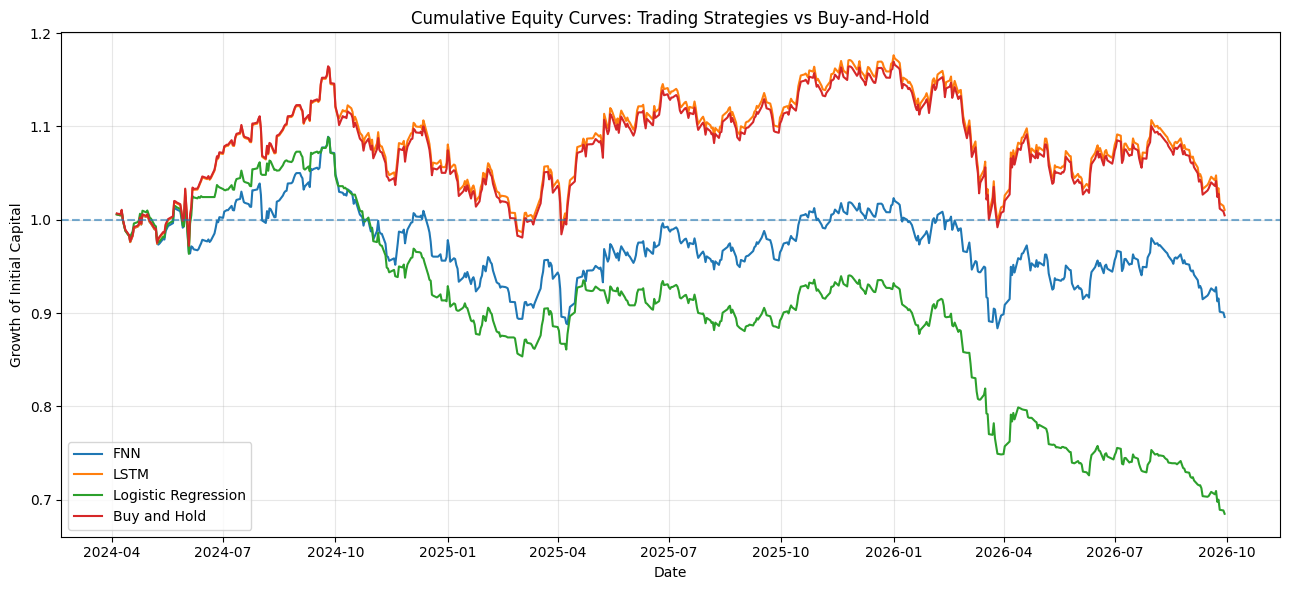

In [121]:

plt.figure(figsize=(13, 6))

for name, result in strategy_returns.items():
    equity_curve = (1 + result["Net_Return"]).cumprod()

    plt.plot(
        equity_curve.index,
        equity_curve.values,
        label=name
    )

plt.axhline(1, linestyle="--", alpha=0.6)

plt.title("Cumulative Equity Curves: Trading Strategies vs Buy-and-Hold")
plt.xlabel("Date")
plt.ylabel("Growth of Initial Capital")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 12.6 Drawdown Analysis

Drawdown measures the decline in portfolio value from its previous maximum. It provides information about the depth and duration of losses experienced during the backtest.

Let \(E_t\) denote the equity curve and let

$$
H_t=\max_{s\leq t}E_s
$$

represent the running historical peak. Drawdown is defined as

$$
D_t=\frac{E_t}{H_t}-1.
$$

Drawdown values are non-positive. A value of \(-0.10\), for example, indicates that the portfolio is 10% below its previous peak.

Maximum drawdown is the most negative drawdown observed during the evaluation period. It is a useful measure of historical downside risk, although it does not describe every aspect of financial risk.

Comparing drawdowns helps assess whether a model-based strategy reduces historical losses relative to buy-and-hold or merely achieves a different return profile.

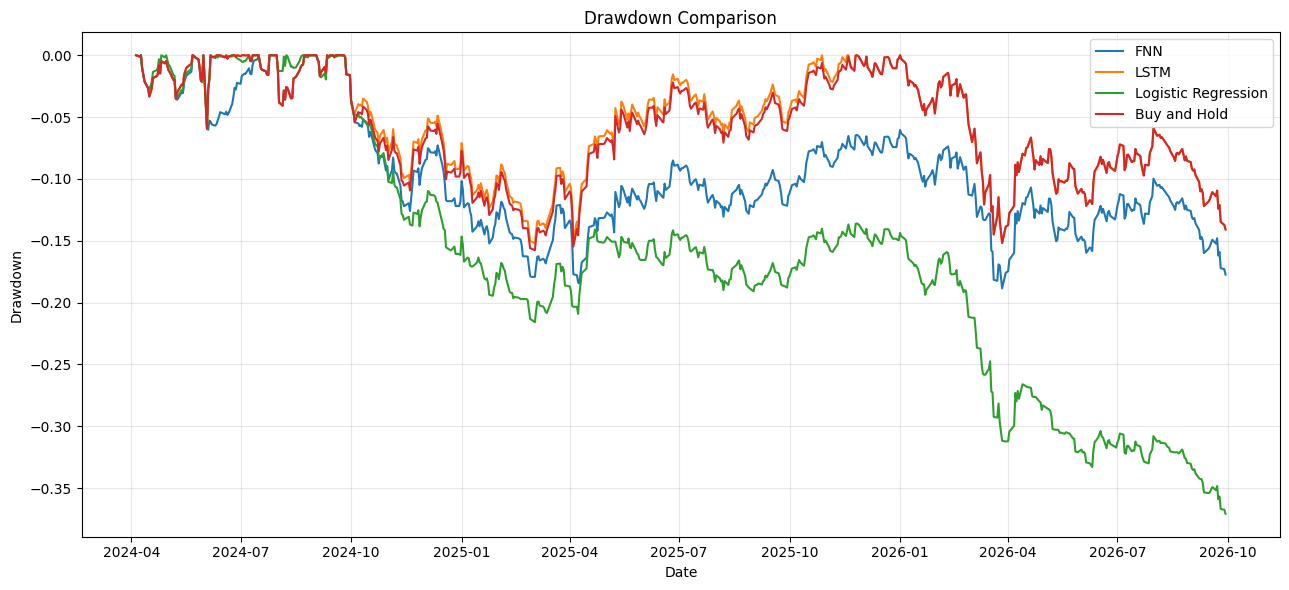

In [122]:

plt.figure(figsize=(13, 6))

for name, result in strategy_returns.items():
    equity_curve = (1 + result["Net_Return"]).cumprod()
    drawdown = equity_curve / equity_curve.cummax() - 1

    plt.plot(
        drawdown.index,
        drawdown.values,
        label=name
    )

plt.title("Drawdown Comparison")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 12.7 Sensitivity to Transaction Costs

Transaction costs can materially affect strategies that frequently change their market exposure. A strategy that appears attractive before costs may become unprofitable when commissions, spreads, taxes, and slippage are considered.

To investigate this effect, we recalculate strategy returns under several assumed one-way transaction-cost rates. The position signals remain fixed throughout this analysis; only the assumed cost changes.

The selected cost rates are illustrative scenarios rather than verified estimates of the total cost of trading the underlying instrument.

The resulting comparison reveals how sensitive the historical performance is to trading expenses. This is particularly important for strategies with high turnover, where repeated position changes may consume a substantial portion of gross returns.

The sensitivity analysis does not identify an optimal transaction-cost rate or prove that the strategies can be implemented at the assumed costs. Realistic implementation would require instrument-specific execution and fee assumptions.

In [123]:

cost_scenarios = [0.0, 0.0005, 0.001, 0.002]

cost_sensitivity_rows = []

for name, result in strategy_returns.items():

    # Buy-and-hold benchmark has no position changes in this simplified
    # model, so its transaction-cost deduction remains zero.
    for cost in cost_scenarios:

        net_returns = (
            result["Gross_Return"]
            - cost * result["Turnover"]
        )

        metrics = calculate_performance_metrics(
            net_returns,
            result["Turnover"]
        )

        cost_sensitivity_rows.append({
            "Strategy": name,
            "One-Way Cost": cost,
            "Total Return": metrics["Total Return"],
            "Annualized Return": metrics["Annualized Return"],
            "Sharpe Ratio": metrics["Sharpe Ratio"],
            "Maximum Drawdown": metrics["Maximum Drawdown"]
        })

cost_sensitivity = pd.DataFrame(cost_sensitivity_rows)

print(cost_sensitivity.round(4).to_string(index=False))


           Strategy  One-Way Cost  Total Return  Annualized Return  Sharpe Ratio  Maximum Drawdown
                FNN        0.0000       -0.0685            -0.0287       -0.1594           -0.1738
                FNN        0.0005       -0.0865            -0.0365       -0.2210           -0.1792
                FNN        0.0010       -0.1042            -0.0442       -0.2825           -0.1885
                FNN        0.0020       -0.1385            -0.0594       -0.4049           -0.2110
               LSTM        0.0000        0.0136             0.0056        0.1089           -0.1518
               LSTM        0.0005        0.0121             0.0049        0.1044           -0.1518
               LSTM        0.0010        0.0106             0.0043        0.0999           -0.1519
               LSTM        0.0020        0.0076             0.0031        0.0909           -0.1536
Logistic Regression        0.0000       -0.1775            -0.0771       -0.6124           -0.2673
Logistic R

### 12.8 Discussion and Limitations

The backtest evaluates a simple long-or-cash strategy based on the probabilities produced by the selected classifiers. The results should be discussed in terms of cumulative return, volatility, Sharpe ratio, maximum drawdown, turnover, and sensitivity to transaction costs.

The analysis should address the following questions:

1. Did any model-based strategy outperform buy-and-hold after the assumed transaction costs?
2. Did the strategy reduce maximum drawdown, and if so, at what cost to total return?
3. Which strategy exhibited the highest turnover?
4. How strongly did transaction costs affect the results?
5. Did classification performance translate into better financial performance?

A model with higher classification accuracy may still perform poorly as a trading strategy. The size and timing of the returns associated with correct and incorrect predictions matter, as do the costs incurred when positions change.

Several limitations must also be acknowledged. The strategy uses a fixed probability threshold, assumes zero return on cash, and does not explicitly simulate bid-ask spreads, market impact, taxes, or execution delays. The assumed transaction-cost rates are illustrative.

In addition, the predictions were generated using models selected on the validation period. The test backtest is therefore a historical evaluation of those fixed predictions, not evidence that the strategy would remain profitable in future markets.

A more comprehensive investigation could include threshold selection using validation data, realistic instrument-specific trading costs, risk-adjusted benchmark comparisons, and a fully chronological walk-forward backtest.

The final conclusion should be determined by the observed results. If the strategies fail to outperform buy-and-hold after costs, that is still a meaningful research finding: directional classification alone may not provide sufficient economic value under the tested assumptions.

In [124]:

print("BACKTEST SUMMARY")
print("=" * 70)

print("\nNet-of-cost performance:")
print(performance_table.round(4).to_string())

print("\nCost sensitivity:")
print(cost_sensitivity.round(4).to_string(index=False))

print("\nInterpretation checklist:")
print("- Compare final cumulative returns.")
print("- Compare annualized volatility and Sharpe ratios.")
print("- Compare maximum drawdowns.")
print("- Examine turnover and cost sensitivity.")
print("- Avoid claiming profitability without evidence.")


BACKTEST SUMMARY

Net-of-cost performance:
                     Total Return  Annualized Return  Annualized Volatility  Sharpe Ratio  Maximum Drawdown  Annualized Turnover
Strategy                                                                                                                        
FNN                       -0.1042            -0.0442                 0.1299       -0.2825           -0.1885              16.0065
LSTM                       0.0106             0.0043                 0.1363        0.0999           -0.1519               1.2313
Logistic Regression       -0.3151            -0.1439                 0.1194       -1.2410           -0.3708              75.1075
Buy and Hold               0.0047             0.0019                 0.1365        0.0825           -0.1577               0.0000

Cost sensitivity:
           Strategy  One-Way Cost  Total Return  Annualized Return  Sharpe Ratio  Maximum Drawdown
                FNN        0.0000       -0.0685            -0.028

## 13. Final Results and Conclusion

In this project, we developed and evaluated four approaches for predicting the next trading day's market direction:

1. **Majority-class baseline:** Predicts the most frequent class in the training data.
2. **Logistic Regression:** Provides a conventional machine-learning benchmark.
3. **Feedforward Neural Network (FNN):** Learns nonlinear relationships between engineered market features.
4. **Long Short-Term Memory (LSTM):** Uses sequences of historical features to learn temporal patterns.

The models were evaluated using a chronological train-validation-test split. Feature scaling was fitted on the training data, validation data was used for model selection, and the test set was reserved for final evaluation.

We also conducted walk-forward validation for Logistic Regression and a simplified trading simulation for the trained models.

The final conclusions should distinguish three questions:

- **Classification performance:** How accurately does the model predict market direction?
- **Trading performance:** Does the model produce favorable returns after the assumed transaction costs?
- **Robustness:** Do the results remain reasonably consistent across different time periods and cost assumptions?

A model with the highest classification accuracy is not automatically the best trading strategy. Prediction errors, the magnitude of market moves, transaction costs, and changes in market conditions can all affect profitability.

This is an exploratory research project, not a claim that future market movements can be predicted reliably.

FINAL TEST-SET CLASSIFICATION RESULTS


,Model,Accuracy,Precision,Recall,F1-Score
0,LSTM,0.5065,0.5057,1.0000,0.6717
1,Majority Class,0.5049,0.5049,1.0000,0.6710
2,FNN,0.4984,0.5017,0.9581,0.6585
3,Logistic Regression,0.4658,0.4817,0.7645,0.5910



BEST MODEL BY CLASSIFICATION METRIC
Accuracy: LSTM (0.5065)
Precision: LSTM (0.5057)
Recall: Majority Class (1.0000)
F1-Score: LSTM (0.6717)


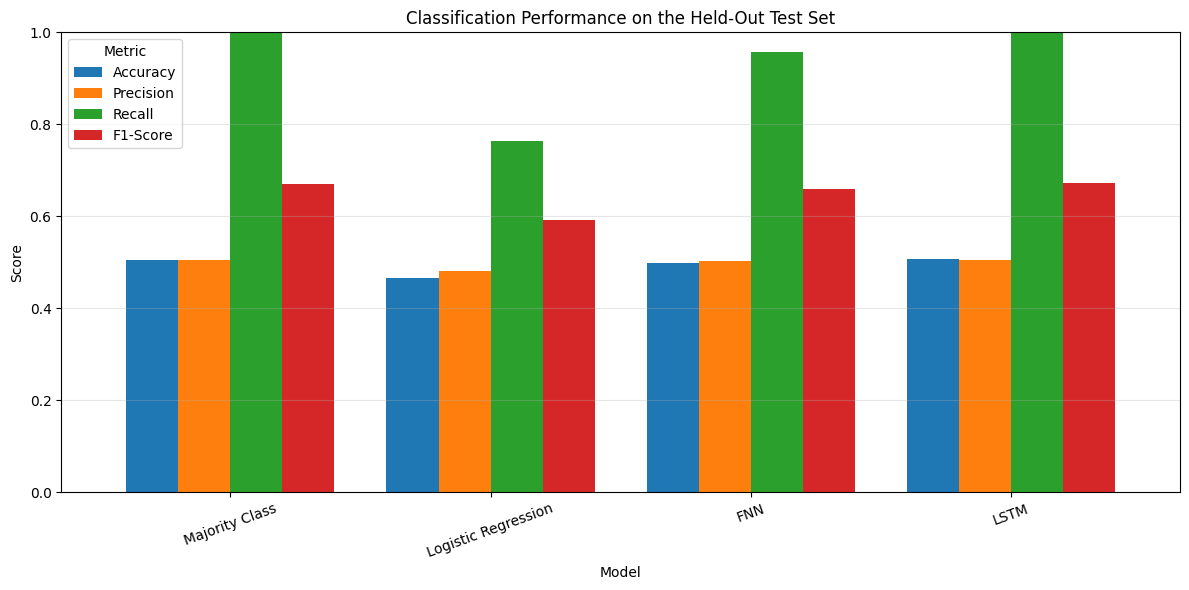

In [126]:

# ============================================================
# SECTION 13.2: FINAL CLASSIFICATION COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as show_table

# Display final test-set classification results
print("FINAL TEST-SET CLASSIFICATION RESULTS")

show_table(
    test_results
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

# Identify the best model for each metric
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

print("\nBEST MODEL BY CLASSIFICATION METRIC")

for metric in metrics:
    best_idx = test_results[metric].idxmax()
    best_model = test_results.loc[best_idx, "Model"]
    best_score = test_results.loc[best_idx, metric]

    print(f"{metric}: {best_model} ({best_score:.4f})")

# Plot comparison of classification metrics
plot_data = test_results.set_index("Model")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Classification Performance on the Held-Out Test Set")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Trading Performance Comparison

The backtesting stage evaluates whether the predictions could have been useful under the simplified trading assumptions used in this project.

We compare the strategies using compounded total return, annualized volatility, Sharpe ratio, maximum drawdown, and turnover. These metrics capture different aspects of performance:

- **Total return:** Overall compounded change in portfolio value.
- **Annualized volatility:** Approximate yearly variability of daily strategy returns.
- **Sharpe ratio:** Return relative to volatility, using a zero risk-free rate in this experiment.
- **Maximum drawdown:** Largest peak-to-trough decline in the equity curve.
- **Annualized turnover:** How frequently the strategy changes its position.

The buy-and-hold benchmark provides a reference point. A strategy should not be judged solely by whether it produces a positive return: its risk, drawdowns, trading costs, and benchmark performance also matter.

In [129]:

# ============================================================
# SECTION 13.3: FINAL TRADING PERFORMANCE COMPARISON
# ============================================================

from IPython.display import display as show_table
import pandas as pd
import matplotlib.pyplot as plt

print("BACKTEST PERFORMANCE SUMMARY")

# Display performance metrics safely
show_table(performance_table.round(4))

# Identify strategy with the highest Sharpe ratio
if "Sharpe Ratio" in performance_table.columns:
    valid_sharpe = performance_table["Sharpe Ratio"].dropna()

    if not valid_sharpe.empty:
        best_sharpe_strategy = valid_sharpe.idxmax()

        print(
            "\nHighest Sharpe ratio:",
            best_sharpe_strategy,
            f"({valid_sharpe.max():.4f})"
        )
    else:
        print("Sharpe ratio is unavailable for all strategies.")
else:
    print("Sharpe Ratio column not found.")
    print("Available columns:", performance_table.columns.tolist())

# Display transaction-cost sensitivity
print("\nTRANSACTION-COST SENSITIVITY")
show_table(cost_sensitivity.round(4))


BACKTEST PERFORMANCE SUMMARY


,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Annualized Turnover
Strategy,,,,,,
FNN,-0.1042,-0.0442,0.1299,-0.2825,-0.1885,16.0065
LSTM,0.0106,0.0043,0.1363,0.0999,-0.1519,1.2313
Logistic Regression,-0.3151,-0.1439,0.1194,-1.2410,-0.3708,75.1075
Buy and Hold,0.0047,0.0019,0.1365,0.0825,-0.1577,0.0000



Highest Sharpe ratio: LSTM (0.0999)

TRANSACTION-COST SENSITIVITY


,Strategy,One-Way Cost,Total Return,Annualized Return,Sharpe Ratio,Maximum Drawdown
0,FNN,0.0000,-0.0685,-0.0287,-0.1594,-0.1738
1,FNN,0.0005,-0.0865,-0.0365,-0.2210,-0.1792
2,FNN,0.0010,-0.1042,-0.0442,-0.2825,-0.1885
3,FNN,0.0020,-0.1385,-0.0594,-0.4049,-0.2110
4,LSTM,0.0000,0.0136,0.0056,0.1089,-0.1518
5,LSTM,0.0005,0.0121,0.0049,0.1044,-0.1518
6,LSTM,0.0010,0.0106,0.0043,0.0999,-0.1519
7,LSTM,0.0020,0.0076,0.0031,0.0909,-0.1536
8,Logistic Regression,0.0000,-0.1775,-0.0771,-0.6124,-0.2673
9,Logistic Regression,0.0005,-0.2494,-0.1111,-0.9273,-0.3210


In [130]:

# ============================================================
# SECTION 13.4: AUTOMATIC RESULTS REPORT
# ============================================================

# Model with the highest test accuracy
best_accuracy_row = test_results.loc[
    test_results["Accuracy"].idxmax()
]

# Model with the highest test F1-score
best_f1_row = test_results.loc[
    test_results["F1-Score"].idxmax()
]

print("=" * 65)
print("NEURAL NETWORK-BASED MARKET DIRECTION CLASSIFICATION")
print("FINAL RESULTS REPORT")
print("=" * 65)

print(f"\nNumber of test observations: {len(y_test)}")
print(f"Test period: {y_test.index.min().date()} to "
      f"{y_test.index.max().date()}")

print("\n1. CLASSIFICATION RESULTS")
print(
    f"Highest accuracy: {best_accuracy_row['Model']} "
    f"({best_accuracy_row['Accuracy']:.4f})"
)
print(
    f"Highest F1-score: {best_f1_row['Model']} "
    f"({best_f1_row['F1-Score']:.4f})"
)

print("\n2. MODEL-SPECIFIC RESULTS")
for _, row in test_results.iterrows():
    print(
        f"{row['Model']}: "
        f"Accuracy={row['Accuracy']:.4f}, "
        f"Precision={row['Precision']:.4f}, "
        f"Recall={row['Recall']:.4f}, "
        f"F1={row['F1-Score']:.4f}"
    )

print("\n3. INTERPRETATION")
print(
    "The best classification model is determined by the selected "
    "evaluation metric. Accuracy and F1-score may select different "
    "models, so both should be considered."
)

print(
    "Trading performance must be evaluated separately using the "
    "backtest results, transaction-cost sensitivity, and drawdowns."
)

print(
    "These results describe the selected historical test period. "
    "They do not guarantee future predictive performance or profitability."
)

print("\n" + "=" * 65)


NEURAL NETWORK-BASED MARKET DIRECTION CLASSIFICATION
FINAL RESULTS REPORT

Number of test observations: 614
Test period: 2024-04-05 to 2026-09-29

1. CLASSIFICATION RESULTS
Highest accuracy: LSTM (0.5065)
Highest F1-score: LSTM (0.6717)

2. MODEL-SPECIFIC RESULTS
Majority Class: Accuracy=0.5049, Precision=0.5049, Recall=1.0000, F1=0.6710
Logistic Regression: Accuracy=0.4658, Precision=0.4817, Recall=0.7645, F1=0.5910
FNN: Accuracy=0.4984, Precision=0.5017, Recall=0.9581, F1=0.6585
LSTM: Accuracy=0.5065, Precision=0.5057, Recall=1.0000, F1=0.6717

3. INTERPRETATION
The best classification model is determined by the selected evaluation metric. Accuracy and F1-score may select different models, so both should be considered.
Trading performance must be evaluated separately using the backtest results, transaction-cost sensitivity, and drawdowns.
These results describe the selected historical test period. They do not guarantee future predictive performance or profitability.



### Conclusion

This project investigates the application of neural networks to financial time-series classification. Historical market data was transformed into engineered features representing recent returns, volatility, moving-average relationships, and momentum. Logistic Regression, a feedforward neural network, and an LSTM were evaluated against a majority-class baseline.

The chronological evaluation design helps reduce temporal leakage, while the held-out test set provides an estimate of performance on observations not used for model selection. Walk-forward validation adds a further check of Logistic Regression across successive historical periods.

The backtesting experiment examines how model predictions translate into hypothetical long-or-cash positions. However, the results depend on simplifying assumptions about execution prices, transaction costs, and portfolio exposure. In particular, a strategy using information from a day's closing price should not assume it can always trade at that same closing price after observing it.

The most important outcome is not necessarily identifying one universally superior model. It is understanding whether the models show evidence of predictive value beyond a simple baseline, whether that value survives realistic trading assumptions, and how stable the results appear across different market conditions.

### Limitations and Future Work

1. **Limited feature set:** The models use technical features derived from historical prices rather than broader economic or company-specific information.
2. **Changing market regimes:** Relationships learned in one period may not persist in another.
3. **Execution assumptions:** The backtest should be extended to use realistic next-open execution, slippage, and transaction costs.
4. **Limited walk-forward model coverage:** Walk-forward validation was implemented for Logistic Regression, not for every neural network.
5. **Hyperparameter selection:** Further tuning should use chronological validation rather than repeatedly optimizing against the test set.
6. **Statistical uncertainty:** Differences in performance may arise from chance. Repeated experiments and additional out-of-sample periods would strengthen the evidence.
7. **Simplified strategy:** The long-or-cash strategy does not model leverage, short selling, taxes, liquidity constraints, or a risk-free return on cash.

Future work could explore additional market features, probability calibration, walk-forward retraining of the FNN and LSTM, multiple market indices, and a more realistic execution engine.

**Final takeaway:** A neural network is useful only if its apparent predictive advantage survives careful out-of-sample testing and realistic assumptions about trading.

In [131]:

from IPython.display import display as show_table

print("FINAL TEST RESULTS")
show_table(test_results.round(4))

print("BACKTEST PERFORMANCE")
show_table(performance_table.round(4))

print("TRANSACTION-COST SENSITIVITY")
show_table(cost_sensitivity.round(4))


FINAL TEST RESULTS


,Model,Accuracy,Precision,Recall,F1-Score
0,Majority Class,0.5049,0.5049,1.0000,0.6710
1,Logistic Regression,0.4658,0.4817,0.7645,0.5910
2,FNN,0.4984,0.5017,0.9581,0.6585
3,LSTM,0.5065,0.5057,1.0000,0.6717


BACKTEST PERFORMANCE


,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Annualized Turnover
Strategy,,,,,,
FNN,-0.1042,-0.0442,0.1299,-0.2825,-0.1885,16.0065
LSTM,0.0106,0.0043,0.1363,0.0999,-0.1519,1.2313
Logistic Regression,-0.3151,-0.1439,0.1194,-1.2410,-0.3708,75.1075
Buy and Hold,0.0047,0.0019,0.1365,0.0825,-0.1577,0.0000


TRANSACTION-COST SENSITIVITY


,Strategy,One-Way Cost,Total Return,Annualized Return,Sharpe Ratio,Maximum Drawdown
0,FNN,0.0000,-0.0685,-0.0287,-0.1594,-0.1738
1,FNN,0.0005,-0.0865,-0.0365,-0.2210,-0.1792
2,FNN,0.0010,-0.1042,-0.0442,-0.2825,-0.1885
3,FNN,0.0020,-0.1385,-0.0594,-0.4049,-0.2110
4,LSTM,0.0000,0.0136,0.0056,0.1089,-0.1518
5,LSTM,0.0005,0.0121,0.0049,0.1044,-0.1518
6,LSTM,0.0010,0.0106,0.0043,0.0999,-0.1519
7,LSTM,0.0020,0.0076,0.0031,0.0909,-0.1536
8,Logistic Regression,0.0000,-0.1775,-0.0771,-0.6124,-0.2673
9,Logistic Regression,0.0005,-0.2494,-0.1111,-0.9273,-0.3210
